In [1]:
import numpy as np
from matplotlib import pyplot as plt
from cycler import cycler
plt.rc('axes', prop_cycle=cycler(color=['0.0', '0.4', '0.8']))
import matplotlib; matplotlib.rcParams.update({'font.size': 18})

In [2]:
from pywrangling.jupyter_slides_functions import apply_beamer_theme
from pywrangling.graphing_functions import use_plotplainblind, set_top_ylabel
import course_helpers as chh
apply_beamer_theme(
    "madrid", skip_font_download=True, author="Robert Pettis", date="Fall 2026",
    show_slide_number=True, cell_tags=True, notebook_path="13-Convolutional-Neural-Networks.ipynb",
)

<IPython.core.display.Javascript object>


✓ Cell tag CSS applied for 48 cell(s):
 cell_index   slide_id                                  tags
          9  slide-1-0 slide_hide_prompt, slide_remove_input
         11  slide-1-1 slide_hide_prompt, slide_remove_input
         13  slide-1-2 slide_hide_prompt, slide_remove_input
         15  slide-1-3 slide_hide_prompt, slide_remove_input
         17  slide-1-4 slide_hide_prompt, slide_remove_input
         20  slide-2-1 slide_hide_prompt, slide_remove_input
         22  slide-2-2 slide_hide_prompt, slide_remove_input
         24  slide-2-3 slide_hide_prompt, slide_remove_input
         26  slide-2-4 slide_hide_prompt, slide_remove_input
         28  slide-2-5 slide_hide_prompt, slide_remove_input
         30  slide-2-6 slide_hide_prompt, slide_remove_input
         32  slide-2-7 slide_hide_prompt, slide_remove_input
         34  slide-2-8 slide_hide_prompt, slide_remove_input
         36  slide-2-9 slide_hide_prompt, slide_remove_input
         38 slide-2-10 slide_hide_prompt, sli

In [3]:
# Presenter clicker remap. Guarded so a student's Restart & Run All
# never breaks on it if pywrangling is missing.
try:
    from pywrangling.jupyter_slides_functions import enable_reveal_key_remap
    enable_reveal_key_remap({
        38: "left",         # Up arrow   -> previous  (clicker left button)
        40: "right",        # Down arrow -> next      (clicker right button)
        27: "up",           # Escape     -> up        (clicker play button)
        66: "down",         # B          -> down      (clicker stop button)
        116: None,          # F5         -> block refresh
        9:  "togglePause",  # Tab        -> black screen
    })
except Exception:
    pass  # not presenting, or pywrangling not installed

In [4]:
# One place that knows the two drawings, the filter, the weights, and how
# to draw grids, windows and the little network. Every slide below supplies
# only its own numbers.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import course_helpers as chh

WINDOW = "#CFE3F5"      # the pale blue of a window on the image
DIM = "#D5D5D5"         # pixels outside the window
MAPFILL = "#2A3B8F"     # feature map cells, shaded by value
POOL = "#E08A1E"        # max pooling colour
RELU_GREEN = "#2E8B57"


def blank_ax(ax):
    ax.set_facecolor("white")
    ax.axis("off")


def frame(figsize, xlim, ylim, dpi=110):
    """A blank white panel with the limits set by hand, since these pictures
       are laid out in data units and must not be autoscaled."""
    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    fig.patch.set_facecolor("white")
    blank_ax(ax)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_aspect("equal")
    return fig, ax


def note(ax, x, y, text, fs=10.0, ha="left", va="center", color=None, weight=None):
    ax.text(x, y, text, ha=ha, va=va, fontsize=fs, linespacing=1.35,
            color=color or chh.INK, weight=weight, zorder=8)


def arrow(ax, a, b, color=None, lw=1.6, style="-|>", rad=0.0):
    ax.annotate("", xy=b, xytext=a, zorder=6,
                arrowprops=dict(arrowstyle=style, color=color or chh.INK, lw=lw,
                                connectionstyle="arc3,rad=%.2f" % rad,
                                shrinkA=2, shrinkB=2))


def grid(ax, M, x, y, cell=0.5, kind="pixels", fs=9.5, title=None, title_fs=9.5,
         fmt="%g", window=None, window_color=None, fills=None, shade=None,
         vmax=None, edge="#9AA0B0", lw=0.8, dim_outside=False, hide_text=False):
    """Draw the matrix M with its top left corner at (x, y). Rows run down the
       page. kind 'pixels': 0 white, 1 black, number inside. kind 'numbers':
       white cells with the number. shade: a colour to fill cells by value
       (1 full, 0 white) instead of black. window = (i, j, h, w) outlines
       that block; with dim_outside the rest is greyed like a slid filter.
       fills: {(i, j): colour} paints single cells. Returns (right, bottom)."""
    M = np.asarray(M, float)
    h, w = M.shape
    top = max(abs(M.max()), abs(M.min()), 1.0) if vmax is None else vmax
    for (i, j), v in np.ndenumerate(M):
        cx, cy = x + j * cell, y - (i + 1) * cell
        inside = window is None or (window[0] <= i < window[0] + window[2]
                                    and window[1] <= j < window[1] + window[3])
        if np.isnan(v):
            ax.add_patch(plt.Rectangle((cx, cy), cell, cell, facecolor="white",
                                       edgecolor=edge, lw=lw, zorder=3))
            continue
        if kind == "pixels":
            face = (shade or "#1A1A1A") if v >= 0.5 else "white"
            if shade is not None:
                face = _mix(shade, v / top)
            text_col = "white" if (v >= 0.5 and shade is None) or (shade and v / top > 0.55) else chh.INK
        else:
            face = "white"
            text_col = chh.INK
            if shade is not None and v > 0:
                face = _mix(shade, 0.15 + 0.75 * v / top)
                text_col = "white" if v / top > 0.55 else chh.INK
        if fills and (i, j) in fills:
            face = fills[(i, j)]
            text_col = chh.INK
        if dim_outside and not inside:
            face = DIM if (kind == "pixels" and v >= 0.5) else ("#F2F2F2" if kind == "pixels" else "white")
            text_col = "#B0B0B0"
        elif window is not None and inside and kind == "pixels" and v < 0.5 and not fills:
            face = WINDOW
        ax.add_patch(plt.Rectangle((cx, cy), cell, cell, facecolor=face,
                                   edgecolor=edge, lw=lw, zorder=3))
        if not hide_text:
            ax.text(cx + cell / 2, cy + cell / 2, fmt % v, ha="center", va="center",
                    fontsize=fs, color=text_col, zorder=4)
    if window is not None:
        i, j, hh, ww = window
        ax.add_patch(plt.Rectangle((x + j * cell, y - (i + hh) * cell), ww * cell, hh * cell,
                                   fill=False, edgecolor=window_color or chh.MADRID,
                                   lw=2.2, zorder=5))
    if title:
        ax.text(x + w * cell / 2, y + 0.12, title, ha="center", va="bottom",
                fontsize=title_fs, color=chh.INK, zorder=4)
    return x + w * cell, y - h * cell


def _mix(color, t):
    """t of the colour over white."""
    import matplotlib.colors as mc
    r, g, b = mc.to_rgb(color)
    t = min(max(t, 0.0), 1.0)
    return (1 - t + t * r, 1 - t + t * g, 1 - t + t * b)


def relu_box(ax, x, y, size=0.75, color=RELU_GREEN):
    """The little box with the bent line, centred at (x, y)."""
    ax.add_patch(FancyBboxPatch((x - size / 2, y - size / 2), size, size,
                                boxstyle="round,pad=0.02", facecolor="white",
                                edgecolor=color, lw=2.0, zorder=5))
    k = size * 0.32
    ax.plot([x - k, x, x + k], [y - k * 0.8, y - k * 0.8, y + k * 0.8],
            color=chh.INK, lw=2.0, zorder=6, solid_capstyle="round")


def box_label(ax, x, y, text, color=POOL, fs=9.0, pad=0.12):
    """A labelled box, centred at (x, y)."""
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, color=color, zorder=7,
            bbox=dict(boxstyle="round,pad=%.2f" % pad, facecolor="white",
                      edgecolor=color, lw=1.6))


def plus_box(ax, x, y, text, color=RELU_GREEN, fs=9.0):
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, color=color, zorder=7,
            bbox=dict(boxstyle="square,pad=0.18", facecolor="white", edgecolor=color, lw=1.4))


def value_box(ax, x, y, text, color, fs=9.5, w=0.55, h=0.46):
    ax.add_patch(plt.Rectangle((x - w / 2, y - h / 2), w, h, facecolor="white",
                               edgecolor=color, lw=1.8, zorder=6))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, color=chh.INK, zorder=7)


# ------------------------------------------------------------------ numerics
IMG_O = np.array([[0, 0, 1, 1, 0, 0],
                  [0, 1, 0, 0, 1, 0],
                  [1, 0, 0, 0, 0, 1],
                  [1, 0, 0, 0, 0, 1],
                  [0, 1, 0, 0, 1, 0],
                  [0, 0, 1, 1, 0, 0]], float)
IMG_X = np.array([[1, 0, 0, 0, 0, 1],
                  [0, 1, 0, 0, 1, 0],
                  [0, 0, 1, 1, 0, 0],
                  [0, 0, 1, 1, 0, 0],
                  [0, 1, 0, 0, 1, 0],
                  [1, 0, 0, 0, 0, 1]], float)
FILTER = np.array([[0, 0, 1],
                   [0, 1, 0],
                   [1, 0, 0]], float)
FILTER_BEFORE = np.array([[1, 0, 1],
                          [0, 0, 1],
                          [1, 1, 0]], float)
BIAS = -2.0
W_IN = np.array([-0.8, -0.07, 0.2, 0.17])
B_HID = 0.97
W_OUT = {"O": -1.33, "X": 1.33}
B_OUT = {"O": 1.45, "X": -0.45}
NODE_COLORS = ["#C2185B", "#7A7A7A", "#2A7FC1", POOL]


def shift_right(img):
    out = np.zeros_like(img)
    out[:, 1:] = img[:, :-1]
    return out


def convolve(img, filt):
    """Slide the filter, multiply the overlapping cells, add them up."""
    kh, kw = filt.shape
    out = np.zeros((img.shape[0] - kh + 1, img.shape[1] - kw + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            out[i, j] = np.sum(img[i:i + kh, j:j + kw] * filt)
    return out


def relu(M):
    return np.maximum(M, 0)


def max_pool(M, size=2):
    h, w = M.shape[0] // size, M.shape[1] // size
    return np.array([[M[i * size:(i + 1) * size, j * size:(j + 1) * size].max()
                      for j in range(w)] for i in range(h)])


def avg_pool(M, size=2):
    h, w = M.shape[0] // size, M.shape[1] // size
    return np.array([[M[i * size:(i + 1) * size, j * size:(j + 1) * size].mean()
                      for j in range(w)] for i in range(h)])


def classify(img, filt=FILTER, bias=BIAS, w_in=W_IN, b_hid=B_HID, w_out=W_OUT, b_out=B_OUT):
    """Everything the little CNN computes for one image, step by step."""
    r = {}
    r["fmap"] = convolve(img, filt) + bias
    r["post"] = relu(r["fmap"])
    r["pooled"] = max_pool(r["post"])
    r["inputs"] = r["pooled"].flatten()
    r["sum"] = float(r["inputs"] @ w_in + b_hid)
    r["hidden"] = max(0.0, r["sum"])
    r["O"] = r["hidden"] * w_out["O"] + b_out["O"]
    r["X"] = r["hidden"] * w_out["X"] + b_out["X"]
    return r


# ----------------------------------------------------------------- diagrams
def products_text(patch, filt):
    """The nine products of one window, three per line, and their sum."""
    lines = []
    for i in range(3):
        lines.append(" + ".join("(%g x %g)" % (patch[i, j], filt[i, j]) for j in range(3)))
    return lines, float(np.sum(patch * filt))


def network(ax, x, y, inputs, cell=0.5, gap=0.62, fs=8.5, w_in=W_IN, b_hid=B_HID,
            w_out=W_OUT, b_out=B_OUT, show_values=True, outputs_at=None):
    """The four input nodes at (x, y) down the page, their weights into the
       sum, the bias, the ReLU, and the two outputs. Returns the numbers."""
    inputs = np.asarray(inputs, float)
    ys = [y - k * gap for k in range(len(inputs))]
    for k, (v, c) in enumerate(zip(inputs, NODE_COLORS)):
        value_box(ax, x, ys[k], "%g" % v, c, fs=fs + 0.5, w=cell, h=cell * 0.9)
    sx, sy = x + 2.4, y - 1.5 * gap
    for k, (v, c) in enumerate(zip(inputs, NODE_COLORS)):
        ax.plot([x + cell / 2, x + 1.0, sx - 0.55], [ys[k], ys[k], sy], color=c, lw=1.4, zorder=4)
        ax.text(x + 1.05, ys[k] + 0.14, "x %g" % w_in[k], ha="left", va="bottom",
                fontsize=fs - 0.5, color=c, zorder=7)
    total = float(inputs @ w_in + b_hid)
    hidden = max(0.0, total)
    note(ax, sx - 0.5, sy, "Sum", fs=fs, ha="left")
    plus_box(ax, sx + 0.75, sy, "+ %g" % b_hid, fs=fs - 0.5)
    rx = sx + 2.1
    arrow(ax, (sx + 1.3, sy), (rx - 0.42, sy), lw=1.2)
    relu_box(ax, rx, sy, size=0.7)
    ox = rx + 3.3
    for name, dy, w, b in (("O", 1.05, w_out["O"], b_out["O"]), ("X", -1.05, w_out["X"], b_out["X"])):
        oy = sy + dy
        ax.plot([rx + 0.36, ox - 1.05], [sy, oy], color=RELU_GREEN, lw=1.3, zorder=4)
        ax.text(rx + 1.3, sy + 0.5 * dy + (0.14 if dy > 0 else -0.14), "x %g" % w, ha="center",
                va="bottom" if dy > 0 else "top", fontsize=fs - 0.5, color=RELU_GREEN, zorder=7)
        val = hidden * w + b
        plus_box(ax, ox - 0.45, oy, "+ %g" % b, fs=fs - 0.5)
        ax.text(ox + 0.22, oy, "=", ha="center", va="center", fontsize=fs, color=chh.INK)
        value_box(ax, ox + 0.98, oy, ("%.2f" % val) if show_values else "?", RELU_GREEN, fs=fs + 0.5, w=0.8)
        ax.text(ox + 1.75, oy, name, ha="center", va="center", fontsize=fs + 5, color=chh.INK, weight="bold")
    if show_values:
        note(ax, sx + 0.35, sy - 0.5, "= %.2f" % total, fs=fs - 0.5, ha="center", color=chh.FITLINE)
        note(ax, rx + 0.35, sy - 0.62, "ReLU: %.2f" % hidden, fs=fs - 0.5, ha="center", color=RELU_GREEN)
    return dict(sum=total, hidden=hidden, O=hidden * w_out["O"] + b_out["O"],
                X=hidden * w_out["X"] + b_out["X"], right=ox + 1.9, bottom=min(ys) - 0.4)


def pipeline(ax, img, cell=0.5, x0=0.0, y0=0.0, show_numbers=True, fs=8.5, filt=FILTER,
             bias=BIAS, title_fs=8.5):
    """The whole picture: image, filter and bias, feature map, ReLU, the map
       after ReLU, max pooling, the pooled grid, the column of inputs, and
       the network. Laid out from (x0, y0), the top left."""
    r = classify(img, filt, bias)
    # top row: filter -> feature map -> ReLU -> post -> pool -> pooled
    gx, gy = x0 + 6 * cell + 1.3, y0
    fx, fy = gx, gy - 0.5 * cell
    grid(ax, filt, fx, fy, cell, kind="pixels", fs=fs, title="Filter", title_fs=title_fs)
    plus_box(ax, fx + 1.5 * cell, fy - 3 * cell - 0.42, "+ %g" % bias, fs=fs - 0.5)
    mx = fx + 3 * cell + 0.95
    arrow(ax, (fx + 3 * cell + 0.08, fy - 1.5 * cell), (mx - 0.08, fy - 1.5 * cell), lw=1.2)
    grid(ax, r["fmap"], mx, gy, cell, kind="numbers", fs=fs, title="Feature Map", title_fs=title_fs)
    rx = mx + 4 * cell + 0.75
    arrow(ax, (mx + 4 * cell + 0.08, gy - 2 * cell), (rx - 0.42, gy - 2 * cell), lw=1.2)
    relu_box(ax, rx, gy - 2 * cell, size=0.7)
    px = rx + 0.75
    arrow(ax, (rx + 0.42, gy - 2 * cell), (px - 0.08, gy - 2 * cell), lw=1.2)
    grid(ax, r["post"], px, gy, cell, kind="numbers", fs=fs, title="After ReLU", title_fs=title_fs,
         shade=MAPFILL)
    bx = px + 4 * cell + 1.2
    arrow(ax, (px + 4 * cell + 0.08, gy - 2 * cell), (bx - 0.95, gy - 2 * cell), lw=1.2, color=POOL)
    box_label(ax, bx, gy - 2 * cell, "Max Pooling", fs=fs - 0.5)
    qx = bx + 1.35
    arrow(ax, (bx + 0.95, gy - 2 * cell), (qx - 0.08, gy - 2 * cell), lw=1.2, color=POOL)
    grid(ax, r["pooled"], qx, gy - cell, cell, kind="numbers", fs=fs, title="Pooled", title_fs=title_fs,
         shade=POOL)
    # bottom left: the image, with an arrow up to the filter
    ix, iy = x0, y0 - 0.4
    grid(ax, img, ix, iy, cell, kind="pixels", fs=fs, title="Input Image", title_fs=title_fs)
    arrow(ax, (ix + 6 * cell + 0.08, iy - 3 * cell), (fx - 0.08, fy - 1.5 * cell), lw=1.2, color=chh.MADRID)
    # bottom right: the column of inputs and the network
    nx, ny = qx + 2 * cell + 1.1, gy - 0.1
    for k in range(4):
        i, j = divmod(k, 2)
        ax.plot([qx + (j + 0.5) * cell, nx - 0.3], [gy - cell - (i + 0.5) * cell, ny - k * 0.62],
                color=NODE_COLORS[k], lw=0.9, zorder=2, alpha=0.8)
    net = network(ax, nx, ny, r["inputs"], cell=cell, fs=fs, show_values=show_numbers)
    note(ax, nx - 0.55, ny + 0.5, "Input to NN", fs=title_fs, ha="left")
    return r, net


def color_pipeline(ax, rgb, cfilter, bias=BIAS, cell=0.5, x0=0.0, y0=0.0, show_numbers=True,
                   fs=8.5, title_fs=8.5, chan_cell=0.36,
                   chan_colors=("#D62828", "#2E8B57", "#2A7FC1")):
    """The same machine as pipeline(), with a color picture going in: three
       channel grids stacked down the left, three filter grids beside them,
       all 27 products added into one feature map, then the bias, ReLU,
       max pooling and the four input network as before."""
    rgb = np.asarray(rgb, float)
    names = ("red", "green", "blue")
    r = {}
    r["fmap"] = sum(convolve(rgb[..., k], cfilter[k]) for k in range(3)) + bias
    r["post"] = relu(r["fmap"])
    r["pooled"] = max_pool(r["post"])
    r["inputs"] = r["pooled"].flatten()
    # left: the three channels, stacked
    gap = 0.55
    ch_h = 6 * chan_cell
    cys = [y0 - 0.4 - k * (ch_h + gap) for k in range(3)]
    for k in range(3):
        grid(ax, rgb[..., k], x0, cys[k], chan_cell, kind="pixels", fs=fs - 1.5, shade=chan_colors[k],
             title=names[k] + " channel", title_fs=title_fs)
    # the three filters, stacked beside their channels
    fx = x0 + 6 * chan_cell + 1.15
    fcell = 0.4
    f_h = 3 * fcell
    fys = [cys[k] - ch_h / 2 + f_h / 2 for k in range(3)]
    for k in range(3):
        grid(ax, cfilter[k], fx, fys[k], fcell, kind="numbers", fs=fs, title="filter, " + names[k],
             title_fs=title_fs - 0.5, edge=chan_colors[k], lw=1.4)
        arrow(ax, (x0 + 6 * chan_cell + 0.08, cys[k] - ch_h / 2), (fx - 0.08, fys[k] - f_h / 2),
              lw=1.2, color=chan_colors[k])
    # all three into one feature map, then the bias
    gy = y0
    mx = fx + 3 * fcell + 1.35
    for k in range(3):
        arrow(ax, (fx + 3 * fcell + 0.08, fys[k] - f_h / 2), (mx - 0.1, gy - 2 * cell), lw=1.2,
              color=chan_colors[k], rad=-0.12 if k == 0 else (0.12 if k == 2 else 0.0))
    plus_box(ax, mx + 2 * cell, gy - 4 * cell - 0.42, "+ %g" % bias, fs=fs - 0.5)
    grid(ax, r["fmap"], mx, gy, cell, kind="numbers", fs=fs, title="Feature Map", title_fs=title_fs)
    rx = mx + 4 * cell + 0.75
    arrow(ax, (mx + 4 * cell + 0.08, gy - 2 * cell), (rx - 0.42, gy - 2 * cell), lw=1.2)
    relu_box(ax, rx, gy - 2 * cell, size=0.7)
    px = rx + 0.75
    arrow(ax, (rx + 0.42, gy - 2 * cell), (px - 0.08, gy - 2 * cell), lw=1.2)
    grid(ax, r["post"], px, gy, cell, kind="numbers", fs=fs, title="After ReLU", title_fs=title_fs,
         shade=MAPFILL)
    bx = px + 4 * cell + 1.2
    arrow(ax, (px + 4 * cell + 0.08, gy - 2 * cell), (bx - 0.95, gy - 2 * cell), lw=1.2, color=POOL)
    box_label(ax, bx, gy - 2 * cell, "Max Pooling", fs=fs - 0.5)
    qx = bx + 1.35
    arrow(ax, (bx + 0.95, gy - 2 * cell), (qx - 0.08, gy - 2 * cell), lw=1.2, color=POOL)
    grid(ax, r["pooled"], qx, gy - cell, cell, kind="numbers", fs=fs, title="Pooled", title_fs=title_fs,
         shade=POOL)
    nx, ny = qx + 2 * cell + 1.1, gy - 0.1
    for k in range(4):
        i, j = divmod(k, 2)
        ax.plot([qx + (j + 0.5) * cell, nx - 0.3], [gy - cell - (i + 0.5) * cell, ny - k * 0.62],
                color=NODE_COLORS[k], lw=0.9, zorder=2, alpha=0.8)
    net = network(ax, nx, ny, r["inputs"], cell=cell, fs=fs, show_values=show_numbers)
    note(ax, nx - 0.55, ny + 0.5, "Input to NN", fs=title_fs, ha="left")
    r.update(net if isinstance(net, dict) else {})
    return r, net

<div class="beamer-meta" data-author="Robert Pettis" data-date="Fall 2026"></div>

# Convolutional Neural Networks

### Neural networks that look at images

Causal Machine Learning

## Before We Start: Updating Your Repo

<span style="display:inline-block; background:#73000A; color:#fff; padding:2px 12px; border-radius:8px; font-weight:700; font-size:.9em;">Reminder</span> &nbsp;same git rhythm as the setup lecture.

| command | what it does |
|---|---|
| `git pull upstream main` | grab today's lecture before class |
| `git checkout -b ps1` | a branch for your own work |
| `git add .` then `git commit -m "..."` | snapshot your changes |
| `git push origin ps1` | send it to your fork, then open a pull request |
| `git status` | what changed, any time |

### Last Time: Classification

- Logit is one node with a sigmoid, trained on <b style="color:#73000A;">cross entropy</b>
- <b style="color:#73000A;">SoftMax</b> turns a network's raw outputs into probabilities that add to 1, and ArgMax reads off the answer
- K nearest neighbors classifies by a <b style="color:#73000A;">vote</b> among the closest training points, and with many inputs nobody is near
- An image has thousands of inputs. Today the classifier is a network again, with the SoftMax output from lecture 12

### Where We Are Going

- Two 6 by 6 drawings, an <b style="color:#73000A;">O</b> and an <b style="color:#73000A;">X</b>, and a computer that has to say which is which
- Three reasons an ordinary network struggles with pictures
- A <b style="color:#73000A;">filter</b> slides across the picture, then ReLU, then <b style="color:#73000A;">max pooling</b>, then the network from lecture 10
- Every number by hand on the O, on the X, and on an X nudged one pixel to the right
- Color: three grids instead of one
- Handwritten digits off old forms, trained live
- A case study: poverty measured from satellite pictures

## Three Problems With Pictures

A friend plays tic-tac-toe against the computer and can never remember whether
the game starts with an X or an O. So every game, the computer has to work out
which letter was drawn.

Zoom in on the screen and each letter is a grid of pixels. Here they are
<b style="color:#73000A;">6 pixels by 6</b>, white or black. Write a white pixel as <b style="color:#73000A;">0</b> and a
black one as <b style="color:#73000A;">1</b> and each drawing is 36 numbers.

(10.399999999999999, -3.5999999999999996)

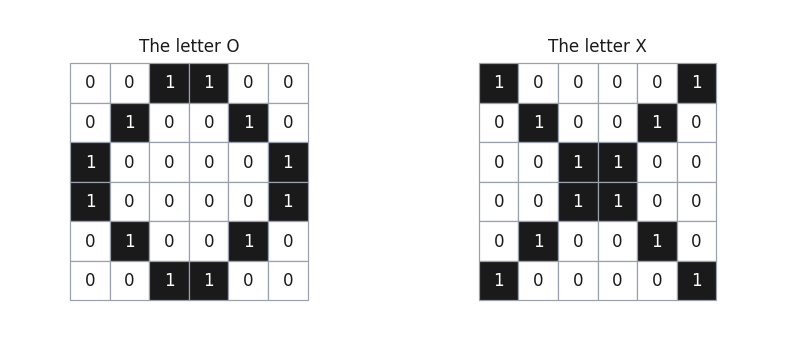

In [5]:
fig, ax = frame((9.2, 4.0), (-0.3, 11.6), (-4.2, 0.8))
grid(ax, IMG_O, 0.6, 0.0, 0.6, kind="pixels", fs=11, title="The letter O", title_fs=11)
grid(ax, IMG_X, 6.8, 0.0, 0.6, kind="pixels", fs=11, title="The letter X", title_fs=11)

### Problem 1: Too Many Weights

- Stack the 36 pixels into a column of input nodes and connect them to one hidden node: <b style="color:#73000A;">36 weights</b>, each one found by backpropagation
- Every extra hidden node is another 36
- A 100 by 100 picture is still small, and it is <b style="color:#73000A;">10,000 weights per hidden node</b>. This does not scale

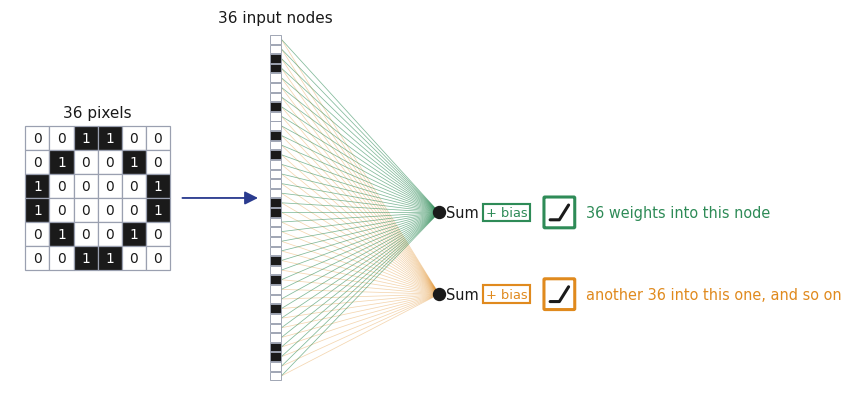

In [6]:
fig, ax = frame((11.6, 4.6), (-0.3, 14.2), (-7.2, 0.9))
grid(ax, IMG_O, 0.0, -1.5, 0.5, kind="pixels", fs=9, title="36 pixels", title_fs=10)
flat = IMG_O.flatten()
cx, top, step = 5.2, 0.3, 0.2
for k, v in enumerate(flat):
    y = top - k * step
    ax.add_patch(plt.Rectangle((cx - 0.12, y - 0.09), 0.24, 0.18, zorder=3,
                               facecolor="#1A1A1A" if v else "white", edgecolor="#9AA0B0", lw=0.6))
    ax.plot([cx + 0.12, 8.6], [y, -3.3], color=RELU_GREEN, lw=0.5, alpha=0.6, zorder=2)
    ax.plot([cx + 0.12, 8.6], [y, -5.0], color=POOL, lw=0.5, alpha=0.35, zorder=1)
arrow(ax, (3.2, -3.0), (cx - 0.3, -3.0), lw=1.2, color=chh.MADRID)
note(ax, cx, top + 0.45, "36 input nodes", fs=10, ha="center")
for y, col, txt in ((-3.3, RELU_GREEN, "36 weights into this node"), (-5.0, POOL, "another 36 into this one, and so on")):
    ax.scatter([8.6], [y], s=60, color=chh.INK, zorder=5)
    note(ax, 8.75, y, "Sum", fs=9.5)
    plus_box(ax, 10.0, y, "+ bias", color=col, fs=8.5)
    relu_box(ax, 11.1, y, size=0.6, color=col)
    note(ax, 11.65, y, txt, fs=9.5, color=col)

### Problem 2: A One Pixel Shift

- Train on the O on the left. Then show it the same O drawn <b style="color:#73000A;">one pixel to the right</b>
- Every one of the 36 input nodes now holds a different number. Nothing in the network says the answer is still O

(10.2, -3.5999999999999996)

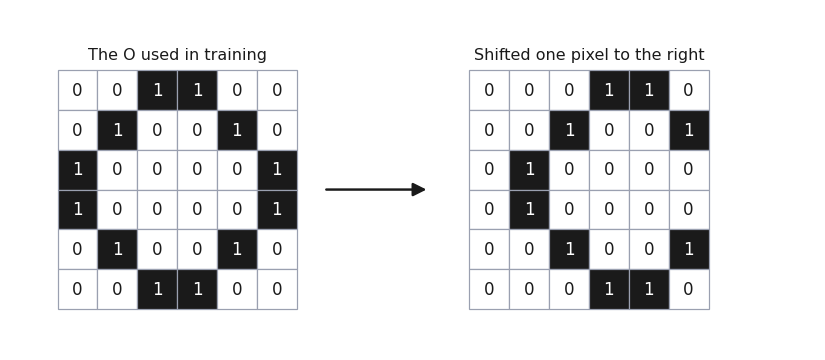

In [7]:
fig, ax = frame((9.6, 4.0), (-0.3, 11.8), (-4.2, 0.9))
grid(ax, IMG_O, 0.4, 0.0, 0.6, kind="pixels", fs=11, title="The O used in training", title_fs=10.5)
arrow(ax, (4.4, -1.8), (6.0, -1.8), lw=1.6)
grid(ax, shift_right(IMG_O), 6.6, 0.0, 0.6, kind="pixels", fs=11, title="Shifted one pixel to the right", title_fs=10.5)

### Problem 3: Neighbors Look Alike

- In a real photo a dark pixel sits among dark pixels and a light pixel among light ones. <b style="color:#73000A;">Nearby pixels are correlated</b>
- Feeding the pixels in one node at a time throws that away. It would be good to use it

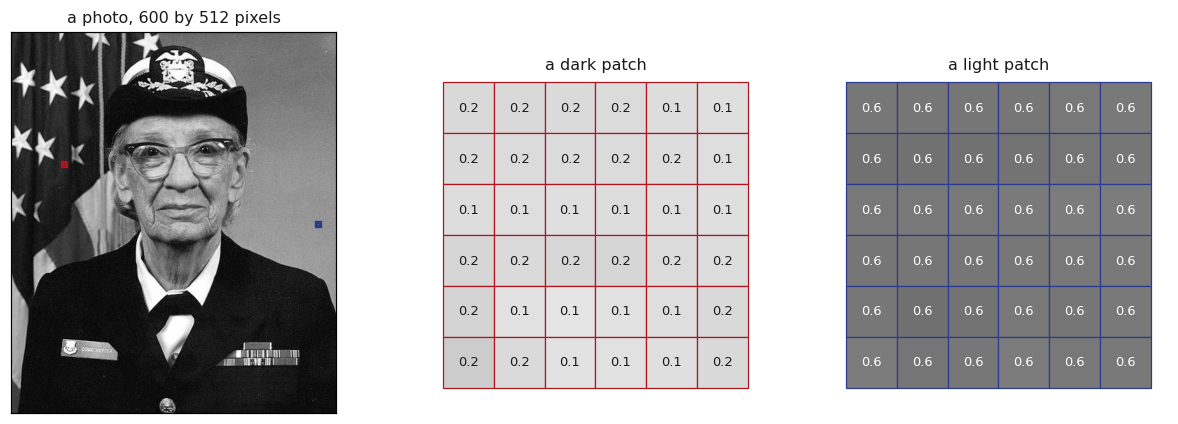

In [8]:
import matplotlib.cbook as cbook
import matplotlib.image as mpimg
photo = mpimg.imread(cbook.get_sample_data("grace_hopper.jpg", asfileobj=False)).mean(axis=2) / 255.0
spots = {"a dark patch": (205, 80), "a light patch": (300, 480)}
fig, axes = plt.subplots(1, 3, figsize=(11.6, 4.2), dpi=110, gridspec_kw={"width_ratios": [1.1, 1, 1]})
fig.patch.set_facecolor("white")
axes[0].imshow(photo, cmap="gray", vmin=0, vmax=1)
axes[0].set_xticks([]); axes[0].set_yticks([])
axes[0].set_title("a photo, 600 by 512 pixels", fontsize=10.5, color=chh.INK)
for (name, (r0, c0)), ax, col in zip(spots.items(), axes[1:], (chh.FITLINE, chh.MADRID)):
    axes[0].add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), 6, 6, fill=False, edgecolor=col, lw=2.2))
    ax.set_facecolor("white"); ax.axis("off"); ax.set_aspect("equal")
    ax.set_xlim(-0.2, 3.8); ax.set_ylim(-3.9, 0.6)
    grid(ax, photo[r0:r0 + 6, c0:c0 + 6], 0.0, 0.0, 0.6, kind="pixels", fs=8.5, fmt="%.1f",
         shade="#1A1A1A", title=name, title_fs=10.5, edge=col)
fig.tight_layout()

### What a CNN Does About All Three

- <b style="color:#73000A;">Fewer input nodes</b> than pixels
- <b style="color:#73000A;">Tolerance to small shifts</b> in where the drawing sits
- Uses the <b style="color:#73000A;">correlations</b> between neighboring pixels

Here is the machine, numbers and all. It looks like a lot. Each piece gets its own slide.

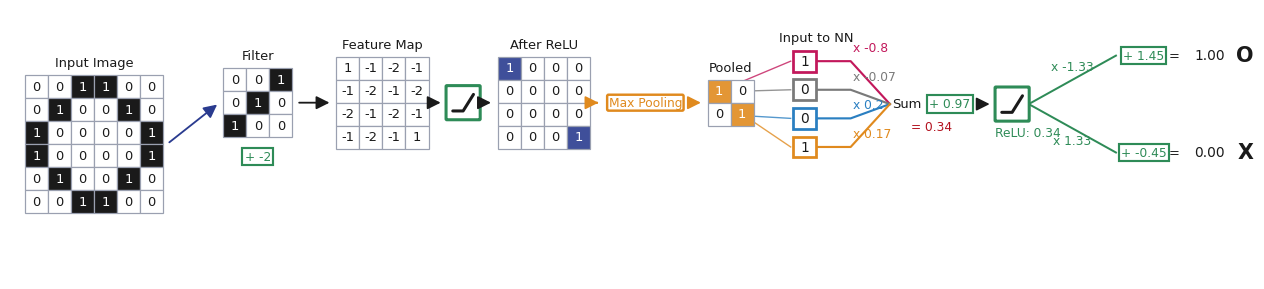

In [9]:
fig, ax = frame((13.8, 4.3), (-0.3, 25.2), (-4.8, 1.0))
_ = pipeline(ax, IMG_O, cell=0.5)

## Step by Step

A <b style="color:#73000A;">convolutional neural network</b>, CNN for short, in the smallest version that
does the job: one filter, one bias, ReLU, one round of max pooling, and a four
input network on the end. Every number below can be checked by hand.

### The Filter

- A <b style="color:#73000A;">filter</b>, also called a kernel, is a small square of numbers, commonly 3 by 3
- Its nine numbers are <b style="color:#73000A;">weights</b>. 
- They start random, and backpropagation sets them
- This one ends up as a diagonal stroke, because a diagonal stroke is what tells an O from an X

(10.299999999999999, -2.0999999999999996)

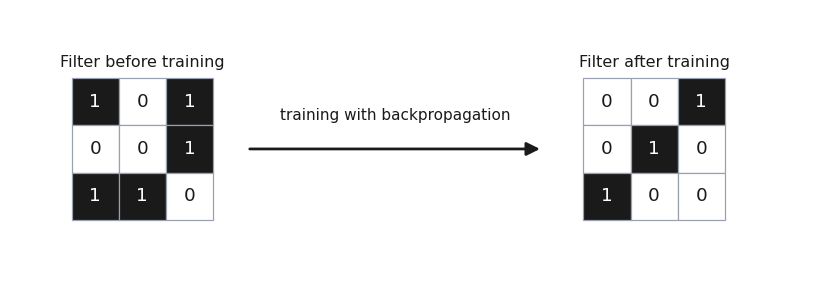

In [10]:
fig, ax = frame((9.4, 3.6), (-0.3, 11.6), (-3.1, 1.0))
grid(ax, FILTER_BEFORE, 0.6, 0.0, 0.7, kind="pixels", fs=12, title="Filter before training", title_fs=10.5)
arrow(ax, (3.2, -1.05), (7.6, -1.05), lw=1.8)
note(ax, 5.4, -0.55, "training with backpropagation", fs=10, ha="center")
grid(ax, FILTER, 8.2, 0.0, 0.7, kind="pixels", fs=12, title="Filter after training", title_fs=10.5)

### Overlay, Multiply, Add

- Lay the filter over the top left corner of the picture
- Multiply each overlapping pair and add the nine products: <b style="color:#73000A;">3</b>
- Fancy name: a sum of products is a <b style="color:#73000A;">dot product</b>. 

- A <b style="color:#73000A;">convolution</b> is an operation that combines two functions or arrays to produce a third one. 
   - By computing the dot product between the input and the filter, the filter is convolved with the input, thus <b style="color:#73000A;">Convolutional Neural Network</b>.

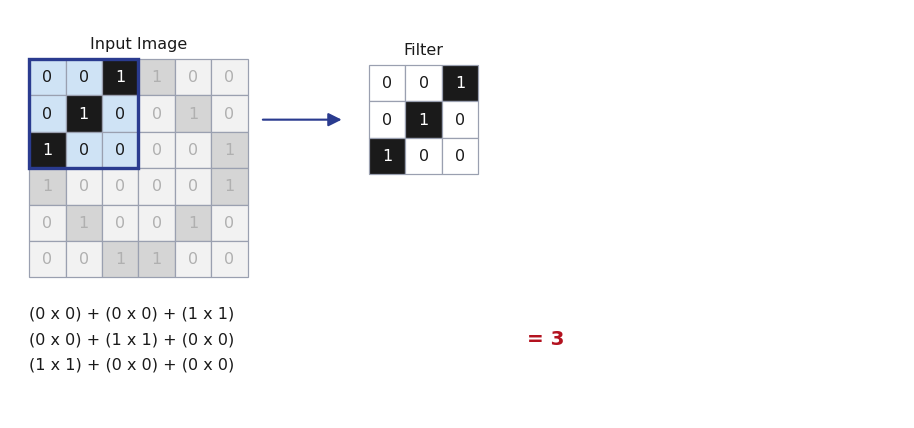

In [11]:
fig, ax = frame((11.6, 4.8), (-0.3, 14.4), (-5.9, 0.8))
grid(ax, IMG_O, 0.0, 0.0, 0.6, kind="pixels", fs=10.5, title="Input Image", title_fs=10.5,
     window=(0, 0, 3, 3), dim_outside=True)
arrow(ax, (3.8, -1.0), (5.2, -1.0), lw=1.4, color=chh.MADRID)
grid(ax, FILTER, 5.6, -0.1, 0.6, kind="pixels", fs=10.5, title="Filter", title_fs=10.5)
lines, s = products_text(IMG_O[0:3, 0:3], FILTER)
for k, ln in enumerate(lines):
    note(ax, 0.0, -4.2 - 0.42 * k, ln, fs=10.5)
note(ax, 8.2, -4.62, "= %g" % s, fs=13, color=chh.FITLINE, weight="bold")

### Add a Bias, Write It Down

- Add a <b style="color:#73000A;">bias</b>, also learned by backpropagation. Here it is −2, so 3 − 2 = <b style="color:#73000A;">1</b>
- The 1 goes into the top left cell of the <b style="color:#73000A;">feature map</b>

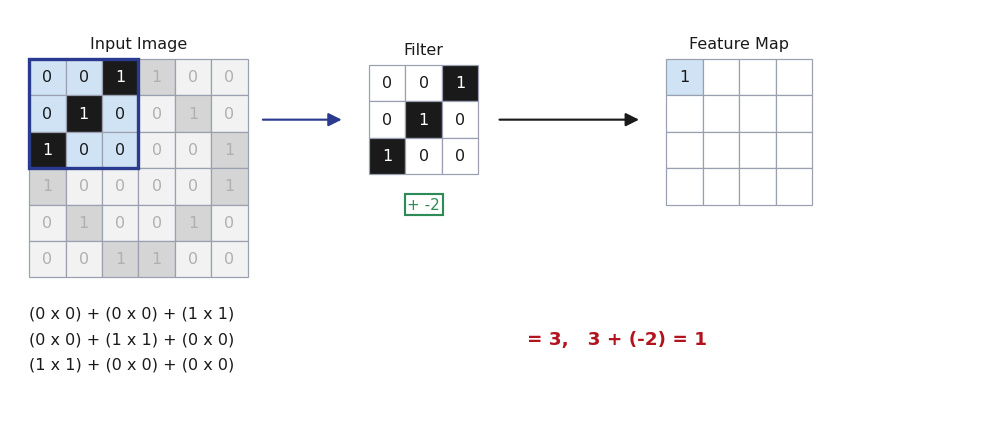

In [12]:
fig, ax = frame((12.4, 4.8), (-0.3, 15.6), (-5.9, 0.8))
grid(ax, IMG_O, 0.0, 0.0, 0.6, kind="pixels", fs=10.5, title="Input Image", title_fs=10.5,
     window=(0, 0, 3, 3), dim_outside=True)
arrow(ax, (3.8, -1.0), (5.2, -1.0), lw=1.4, color=chh.MADRID)
grid(ax, FILTER, 5.6, -0.1, 0.6, kind="pixels", fs=10.5, title="Filter", title_fs=10.5)
plus_box(ax, 6.5, -2.4, "+ %g" % BIAS, fs=10)
shown = np.full((4, 4), np.nan); shown[0, 0] = classify(IMG_O)["fmap"][0, 0]
arrow(ax, (7.7, -1.0), (10.1, -1.0), lw=1.4)
grid(ax, shown, 10.5, 0.0, 0.6, kind="numbers", fs=10.5, title="Feature Map", title_fs=10.5,
     fills={(0, 0): WINDOW})
lines, s = products_text(IMG_O[0:3, 0:3], FILTER)
for k, ln in enumerate(lines):
    note(ax, 0.0, -4.2 - 0.42 * k, ln, fs=10.5)
note(ax, 8.2, -4.62, "= %g,   %g + (%g) = %g" % (s, s, BIAS, s + BIAS), fs=12, color=chh.FITLINE, weight="bold")

### Slide It One Pixel

- Move the filter one column to the right and do it again: dot product 1, plus the bias, <b style="color:#73000A;">−1</b>
- How far it moves each step is the <b style="color:#73000A;">stride</b>. One here. Bigger pictures often use 2 or 3

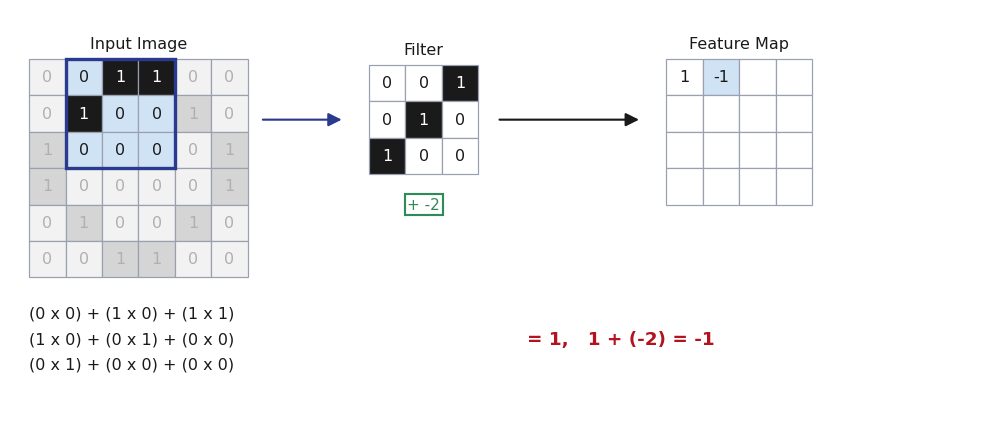

In [13]:
fig, ax = frame((12.4, 4.8), (-0.3, 15.6), (-5.9, 0.8))
grid(ax, IMG_O, 0.0, 0.0, 0.6, kind="pixels", fs=10.5, title="Input Image", title_fs=10.5,
     window=(0, 1, 3, 3), dim_outside=True)
arrow(ax, (3.8, -1.0), (5.2, -1.0), lw=1.4, color=chh.MADRID)
grid(ax, FILTER, 5.6, -0.1, 0.6, kind="pixels", fs=10.5, title="Filter", title_fs=10.5)
plus_box(ax, 6.5, -2.4, "+ %g" % BIAS, fs=10)
fm = classify(IMG_O)["fmap"]
shown = np.full((4, 4), np.nan); shown[0, 0] = fm[0, 0]; shown[0, 1] = fm[0, 1]
arrow(ax, (7.7, -1.0), (10.1, -1.0), lw=1.4)
grid(ax, shown, 10.5, 0.0, 0.6, kind="numbers", fs=10.5, title="Feature Map", title_fs=10.5,
     fills={(0, 1): WINDOW})
lines, s = products_text(IMG_O[0:3, 1:4], FILTER)
for k, ln in enumerate(lines):
    note(ax, 0.0, -4.2 - 0.42 * k, ln, fs=10.5)
note(ax, 8.2, -4.62, "= %g,   %g + (%g) = %g" % (s, s, BIAS, s + BIAS), fs=12, color=chh.FITLINE, weight="bold")

### Keep Going Until the Map Is Full

- Four positions across and four rows down: <b style="color:#73000A;">16 dot products</b>, 16 cells
- The filter cannot hang over the edge, so a 6 by 6 picture and a 3 by 3 filter give a <b style="color:#73000A;">4 by 4</b> map

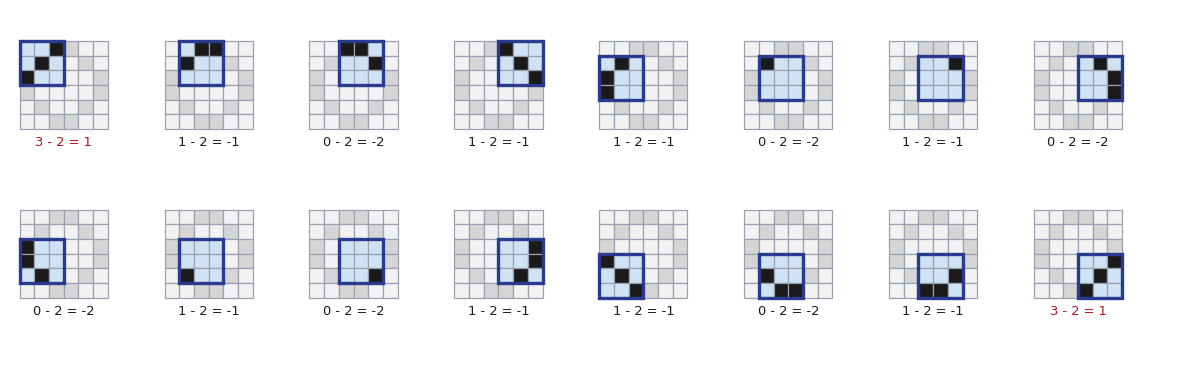

In [14]:
fig, ax = frame((13.8, 4.4), (-0.2, 27.0), (-7.4, 0.7))
fm = classify(IMG_O)["fmap"]
for k in range(16):
    i, j = divmod(k, 4)
    row, col = divmod(k, 8)
    x, y = col * 3.35, -row * 3.9
    grid(ax, IMG_O, x, y, 0.34, kind="pixels", fs=6, window=(i, j, 3, 3), dim_outside=True, hide_text=True)
    s = fm[i, j] - BIAS
    note(ax, x + 1.02, y - 2.35, "%g %s 2 = %g" % (s, "-", fm[i, j]), fs=8.5, ha="center",
         color=chh.FITLINE if fm[i, j] > 0 else chh.INK)

### The Finished Feature Map

- The picture went in, the filter went over it, a bias was added, and a 4 by 4 map came out
- Two cells hold a <b style="color:#73000A;">1</b>: the two places where the filter matched the drawing perfectly

(12.1, -2.4)

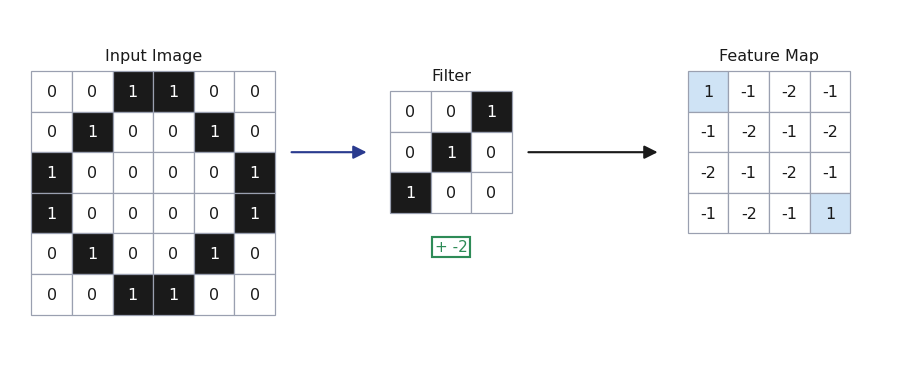

In [15]:
fig, ax = frame((10.4, 4.3), (-0.3, 12.8), (-4.3, 0.9))
grid(ax, IMG_O, 0.0, 0.0, 0.6, kind="pixels", fs=10.5, title="Input Image", title_fs=10.5)
arrow(ax, (3.8, -1.2), (5.0, -1.2), lw=1.4, color=chh.MADRID)
grid(ax, FILTER, 5.3, -0.3, 0.6, kind="pixels", fs=10.5, title="Filter", title_fs=10.5)
plus_box(ax, 6.2, -2.6, "+ %g" % BIAS, fs=10)
arrow(ax, (7.3, -1.2), (9.3, -1.2), lw=1.4)
grid(ax, classify(IMG_O)["fmap"], 9.7, 0.0, 0.6, kind="numbers", fs=10.5, title="Feature Map", title_fs=10.5,
     fills={(0, 0): WINDOW, (3, 3): WINDOW})

### Each Cell Remembers Its Neighborhood

- Every cell of the map came from a 3 by 3 block of <b style="color:#73000A;">neighboring pixels</b>, read together. 
    - This takes advantage of correlations in the image
- The 1 at the bottom right of the map is the diagonal stroke at the bottom right of the O

(12.1, -2.4)

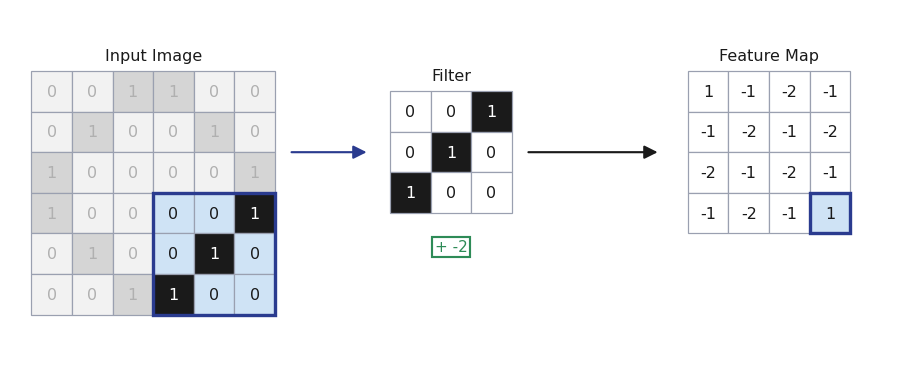

In [16]:
fig, ax = frame((10.4, 4.3), (-0.3, 12.8), (-4.3, 0.9))
grid(ax, IMG_O, 0.0, 0.0, 0.6, kind="pixels", fs=10.5, title="Input Image", title_fs=10.5,
     window=(3, 3, 3, 3), dim_outside=True)
arrow(ax, (3.8, -1.2), (5.0, -1.2), lw=1.4, color=chh.MADRID)
grid(ax, FILTER, 5.3, -0.3, 0.6, kind="pixels", fs=10.5, title="Filter", title_fs=10.5)
plus_box(ax, 6.2, -2.6, "+ %g" % BIAS, fs=10)
arrow(ax, (7.3, -1.2), (9.3, -1.2), lw=1.4)
grid(ax, classify(IMG_O)["fmap"], 9.7, 0.0, 0.6, kind="numbers", fs=10.5, title="Feature Map", title_fs=10.5,
     window=(3, 3, 1, 1), fills={(3, 3): WINDOW})

### ReLU

- Run the map through <b style="color:#73000A;">ReLU</b> from lecture 10: negatives become 0, positives stay what they were
- Two cells survive, the two perfect matches

(10.0, -2.4)

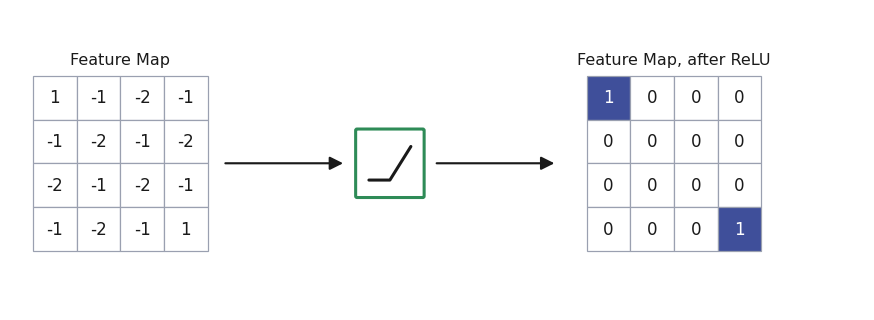

In [17]:
r = classify(IMG_O)
fig, ax = frame((10.0, 3.6), (-0.3, 11.4), (-3.2, 0.9))
grid(ax, r["fmap"], 0.0, 0.0, 0.6, kind="numbers", fs=11, title="Feature Map", title_fs=10.5)
arrow(ax, (2.6, -1.2), (4.3, -1.2), lw=1.4)
relu_box(ax, 4.9, -1.2, size=0.9)
arrow(ax, (5.5, -1.2), (7.2, -1.2), lw=1.4)
grid(ax, r["post"], 7.6, 0.0, 0.6, kind="numbers", fs=11, title="Feature Map, after ReLU", title_fs=10.5, shade=MAPFILL)

### Max Pooling

- A second filter, with no weights to learn: look at a 2 by 2 block and keep the <b style="color:#73000A;">largest</b> value
- It moves so the blocks never overlap, stride 2, so the 4 by 4 map becomes <b style="color:#73000A;">2 by 2</b>
- Keeping the average instead is <b style="color:#73000A;">average pooling</b>. Classifiers mostly use max

(12.0, -1.7999999999999998)

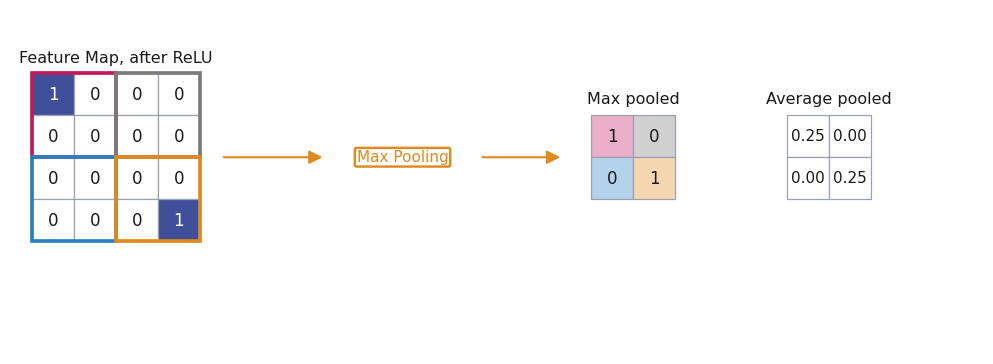

In [18]:
r = classify(IMG_O)
fig, ax = frame((11.4, 4.2), (-0.3, 13.6), (-4.0, 0.9))
grid(ax, r["post"], 0.0, 0.0, 0.6, kind="numbers", fs=11, title="Feature Map, after ReLU", title_fs=10.5, shade=MAPFILL)
blocks = {(0, 0): NODE_COLORS[0], (0, 1): NODE_COLORS[1], (1, 0): NODE_COLORS[2], (1, 1): NODE_COLORS[3]}
for (bi, bj), col in blocks.items():
    ax.add_patch(plt.Rectangle((bj * 1.2, -(bi + 1) * 1.2), 1.2, 1.2, fill=False, edgecolor=col, lw=2.4, zorder=6))
arrow(ax, (2.7, -1.2), (4.2, -1.2), lw=1.4, color=POOL)
box_label(ax, 5.3, -1.2, "Max Pooling", fs=10)
arrow(ax, (6.4, -1.2), (7.6, -1.2), lw=1.4, color=POOL)
grid(ax, r["pooled"], 8.0, -0.6, 0.6, kind="numbers", fs=11, title="Max pooled", title_fs=10.5,
     fills={k: _mix(c, 0.35) for k, c in blocks.items()})
grid(ax, avg_pool(r["post"]), 10.8, -0.6, 0.6, kind="numbers", fs=10, fmt="%.2f", title="Average pooled", title_fs=10.5)

### Where the Filter Matched Best

- The 1 at the top left of the pooled grid came from the top left block of the map, and that block came from the top left quarter of the picture, where the filter sat on the stroke
- So max pooling keeps <b style="color:#73000A;">where the filter did its best job</b>, and forgets where inside the block that was. That is the shift tolerance, and it gets its own slide

(11.2, -1.7999999999999998)

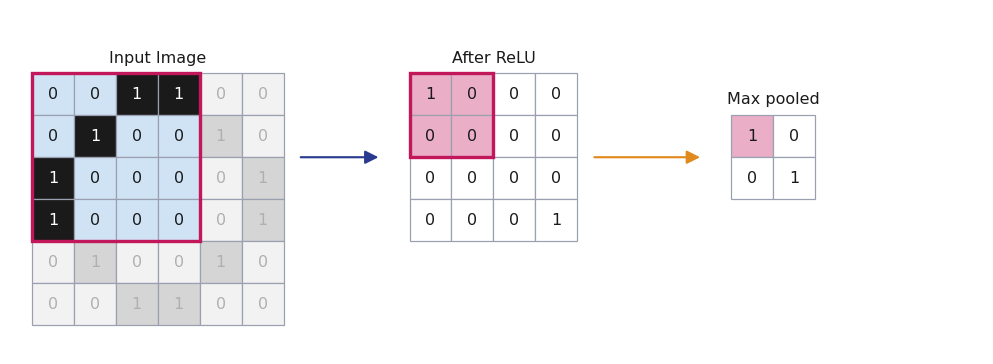

In [19]:
r = classify(IMG_O)
pink = _mix(NODE_COLORS[0], 0.35)
fig, ax = frame((11.4, 4.2), (-0.3, 13.6), (-4.0, 0.9))
grid(ax, IMG_O, 0.0, 0.0, 0.6, kind="pixels", fs=10.5, title="Input Image", title_fs=10.5,
     window=(0, 0, 4, 4), window_color=NODE_COLORS[0], dim_outside=True)
arrow(ax, (3.8, -1.2), (5.0, -1.2), lw=1.4, color=chh.MADRID)
grid(ax, r["post"], 5.4, 0.0, 0.6, kind="numbers", fs=10.5, title="After ReLU", title_fs=10.5,
     window=(0, 0, 2, 2), window_color=NODE_COLORS[0], fills={(0, 0): pink, (0, 1): pink, (1, 0): pink, (1, 1): pink})
arrow(ax, (8.0, -1.2), (9.6, -1.2), lw=1.4, color=POOL)
grid(ax, r["pooled"], 10.0, -0.6, 0.6, kind="numbers", fs=10.5, title="Max pooled", title_fs=10.5,
     fills={(0, 0): pink})

### From Grid to Column

- Read the pooled grid off as a column: <b style="color:#73000A;">1, 0, 0, 1</b>
- Four input nodes. The picture had 36 pixels

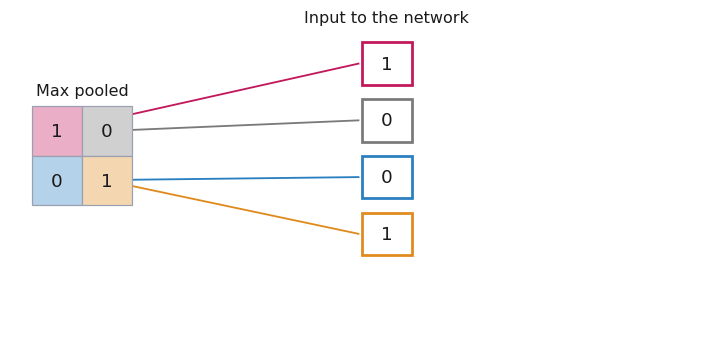

In [20]:
r = classify(IMG_O)
fig, ax = frame((8.2, 3.6), (-0.3, 9.4), (-3.4, 0.9))
grid(ax, r["pooled"], 0.0, -0.3, 0.7, kind="numbers", fs=12, title="Max pooled", title_fs=10.5,
     fills={(0, 0): _mix(NODE_COLORS[0], 0.35), (0, 1): _mix(NODE_COLORS[1], 0.35),
            (1, 0): _mix(NODE_COLORS[2], 0.35), (1, 1): _mix(NODE_COLORS[3], 0.35)})
for k, (v, c) in enumerate(zip(r["inputs"], NODE_COLORS)):
    i, j = divmod(k, 2)
    ax.plot([(j + 0.5) * 0.7, 4.6], [-0.3 - (i + 0.5) * 0.7, 0.3 - 0.8 * k], color=c, lw=1.2, zorder=2)
    value_box(ax, 5.0, 0.3 - 0.8 * k, "%g" % v, c, fs=12, w=0.7, h=0.6)
note(ax, 5.0, 0.95, "Input to the network", fs=10.5, ha="center")

### Into an Ordinary Network

- Four inputs, one hidden node with ReLU, two outputs: one for <b style="color:#73000A;">O</b> and one for <b style="color:#73000A;">X</b>
- The weights and biases below were found by backpropagation on drawings of both letters, lecture 11 again
- The printed version of this example has 1.6 for the hidden bias and −0.45 for the weight into X. The published errata correct them to <b style="color:#73000A;">0.97</b> and <b style="color:#73000A;">1.33</b>, and only the corrected values give the outputs on the next slides

{'sum': 0.33999999999999997,
 'hidden': 0.33999999999999997,
 'O': 0.9978,
 'X': 0.0021999999999999797,
 'right': 10.0,
 'bottom': -2.25}

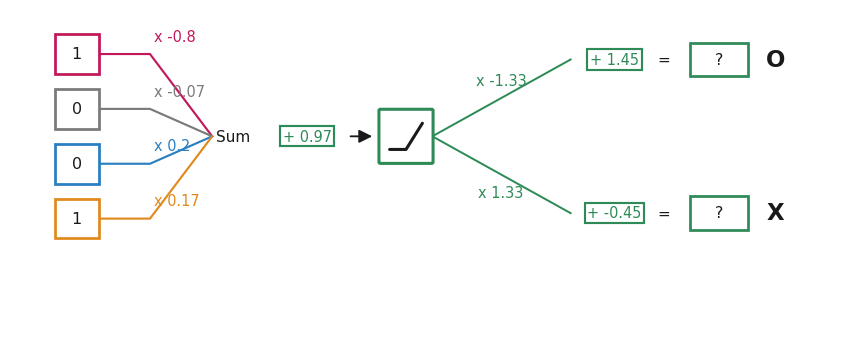

In [21]:
fig, ax = frame((10.4, 3.8), (-0.6, 10.6), (-3.4, 1.0))
network(ax, 0.3, 0.4, classify(IMG_O)["inputs"], cell=0.6, gap=0.75, fs=10, show_values=False)

### The O Comes Out as an O

- Sum: (1 × −0.8) + (0 × −0.07) + (0 × 0.2) + (1 × 0.17) + 0.97 = <b style="color:#73000A;">0.34</b>
- ReLU leaves 0.34, since it is positive
- O output: 0.34 × −1.33 + 1.45 = <b style="color:#73000A;">1.00</b>. X output: 0.34 × 1.33 − 0.45 = <b style="color:#73000A;">0.00</b>

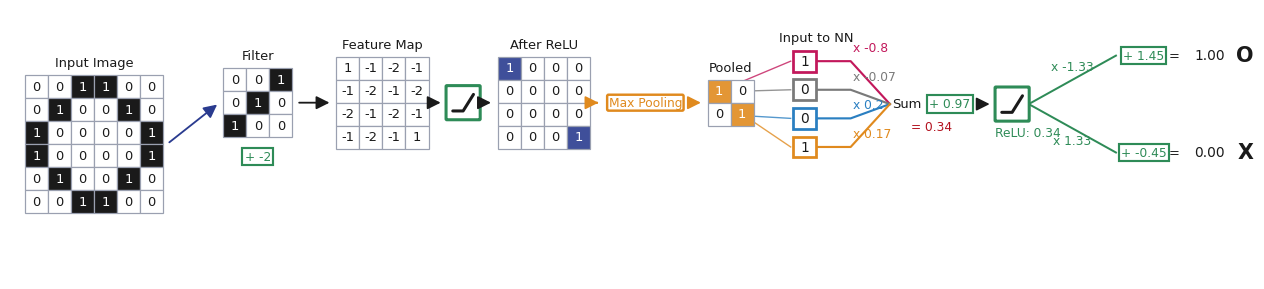

In [22]:
fig, ax = frame((13.8, 4.3), (-0.3, 25.2), (-4.8, 1.0))
r, net = pipeline(ax, IMG_O, cell=0.5)

### Now the X

- Same filter, same bias, same weights. Only the drawing changes
- The feature map, ReLU and pooling give <b style="color:#73000A;">0, 1, 1, 0</b>, the sum is 1.10, and the outputs are <b style="color:#73000A;">0</b> for O and <b style="color:#73000A;">1</b> for X

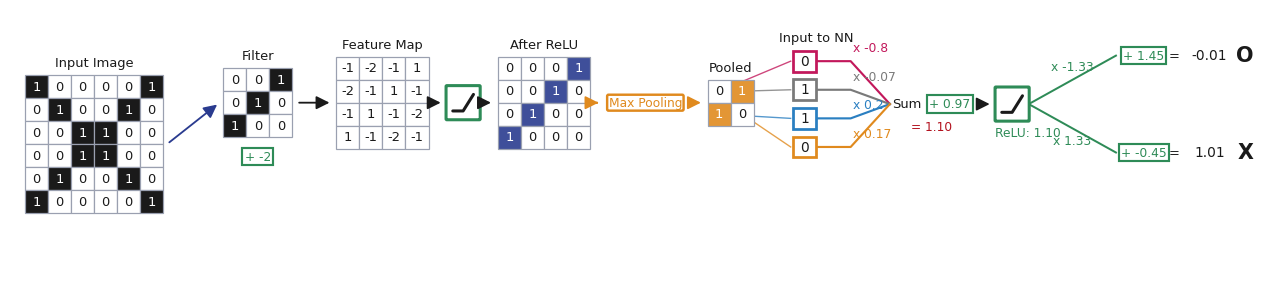

In [23]:
fig, ax = frame((13.8, 4.3), (-0.3, 25.2), (-4.8, 1.0))
r, net = pipeline(ax, IMG_X, cell=0.5)

### 36 Inputs Became 4

- Problem 1: the network on the end has <b style="color:#73000A;">4 inputs</b> and 4 weights into its hidden node, not 36. Bigger pictures use more filters and more pooling, and the count stays small
- Problem 3: the filter reads a 3 by 3 block at a time, so neighbors are used together
- Problem 2 is next

### The X Nudged One Pixel Right

- Shift the X one pixel to the right. Every cell of the feature map changes
- After ReLU and pooling the column is <b style="color:#73000A;">0, 1, 1, 1</b>, one cell away from the X's 0, 1, 1, 0
- Outputs <b style="color:#73000A;">−0.24</b> for O and <b style="color:#73000A;">1.24</b> for X. Still an X. (The source rounds these to −0.2 and 1.23)
- SoftMax from lecture 12 would turn the pair into probabilities, and ArgMax would just say X

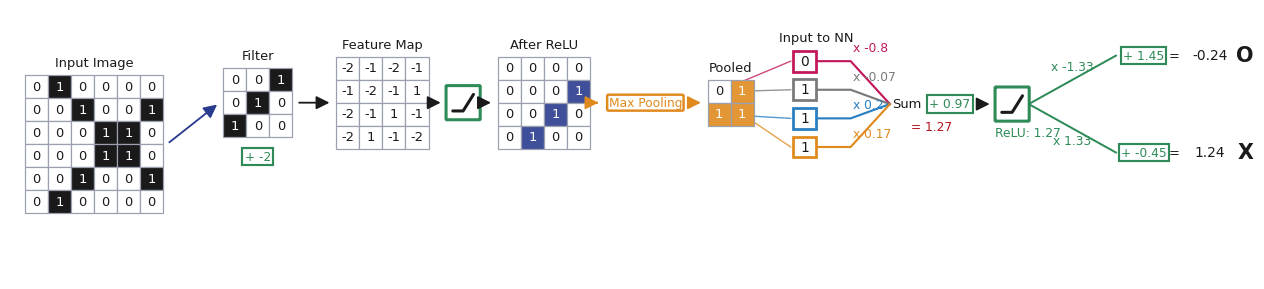

In [24]:
fig, ax = frame((13.8, 4.3), (-0.3, 25.2), (-4.8, 1.0))
r, net = pipeline(ax, shift_right(IMG_X), cell=0.5)

### Bigger CNNs Are More of the Same

- Real ones use <b style="color:#73000A;">many filters</b>, so one picture becomes many feature maps, and they run convolution, ReLU and pooling again on those maps before the ordinary network
- Every piece is still a filter, an activation and a pooling step
- Each layer's maps are the next layer's picture, with as many <b style="color:#73000A;">channels</b> as there were filters...

### In PyTorch

- `nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3)`: one black and white channel in, one filter, 3 by 3
- `nn.MaxPool2d(kernel_size=2, stride=2)`: 2 by 2 blocks that do not overlap
- `nn.Linear` for the rest, as in lecture 10. A picture goes in as a tensor of shape (batch, channels, rows, columns)
- Below, the deck's numbers are loaded into the layers and the three drawings run through

In [25]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class LittleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.hidden = nn.Linear(4, 1)
        self.out = nn.Linear(1, 2)

    def forward(self, x):
        x = self.pool(F.relu(self.conv(x)))      # filter, bias, ReLU, max pooling
        x = F.relu(self.hidden(x.flatten(1)))   # the four inputs into one hidden node
        return self.out(x)                      # one raw output for O, one for X

net = LittleCNN()
with torch.no_grad():
    net.conv.weight[:] = torch.tensor(FILTER, dtype=torch.float32)
    net.conv.bias[:] = BIAS
    net.hidden.weight[:] = torch.tensor(W_IN, dtype=torch.float32)
    net.hidden.bias[:] = B_HID
    net.out.weight[:] = torch.tensor([[W_OUT["O"]], [W_OUT["X"]]])
    net.out.bias[:] = torch.tensor([B_OUT["O"], B_OUT["X"]])
    for name, img in (("the O", IMG_O), ("the X", IMG_X), ("the X shifted right", shift_right(IMG_X))):
        x = torch.tensor(img, dtype=torch.float32).reshape(1, 1, 6, 6)
        o, xx = net(x)[0].tolist()
        print("%-22s input shape %s   O %5.2f   X %5.2f" % (name, tuple(x.shape), o, xx))

the O                  input shape (1, 1, 6, 6)   O  1.00   X  0.00
the X                  input shape (1, 1, 6, 6)   O -0.01   X  1.01
the X shifted right    input shape (1, 1, 6, 6)   O -0.24   X  1.24


## Color: Three Grids Instead of One

- A black and white pixel is one number. A color pixel is <b style="color:#73000A;">three</b>: how much red, green and blue light, each from 0 to 1
- White is 1, 1, 1. Black is 0, 0, 0. A red stroke is 1, 0, 0
- So a color picture is three 6 by 6 grids, called <b style="color:#73000A;">channels</b>, and the same O drawn in red looks like this

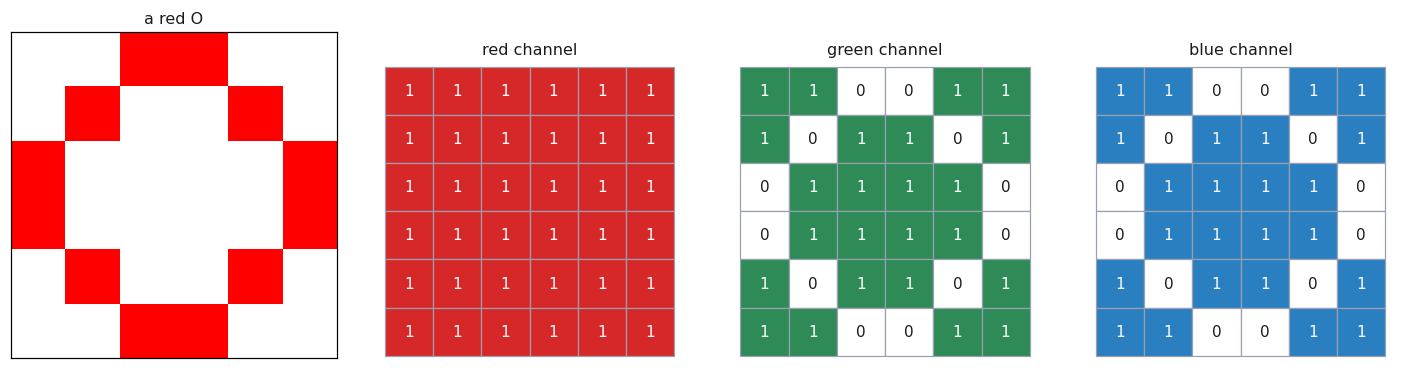

In [26]:
def color_drawing(img, rgb):
    # white background, the stroke painted in the given color
    out = np.ones(img.shape + (3,))
    for k in range(3):
        out[..., k] = np.where(img == 1, rgb[k], 1.0)
    return out

RED_O = color_drawing(IMG_O, (1, 0, 0))
fig, axes = plt.subplots(1, 4, figsize=(13.2, 3.9), dpi=110)
fig.patch.set_facecolor("white")
axes[0].imshow(RED_O, interpolation="nearest")
axes[0].set_xticks([]); axes[0].set_yticks([])
axes[0].set_title("a red O", fontsize=10.5, color=chh.INK)
for k, (ax, name, col) in enumerate(zip(axes[1:], ("red channel", "green channel", "blue channel"),
                                        ("#D62828", "#2E8B57", "#2A7FC1"))):
    ax.set_facecolor("white"); ax.axis("off"); ax.set_aspect("equal")
    ax.set_xlim(-0.2, 3.8); ax.set_ylim(-3.9, 0.7)
    grid(ax, RED_O[..., k], 0.0, 0.0, 0.6, kind="pixels", fs=10, shade=col, title=name, title_fs=10.5)
fig.tight_layout()

### The Red O Is Invisible in Red

- The red channel is all 1s. The drawing is there as <b style="color:#73000A;">missing green</b> and <b style="color:#73000A;">missing blue</b>
- A filter that reads only one channel would never see a red stroke on a white page in the red channel. It has to read all three

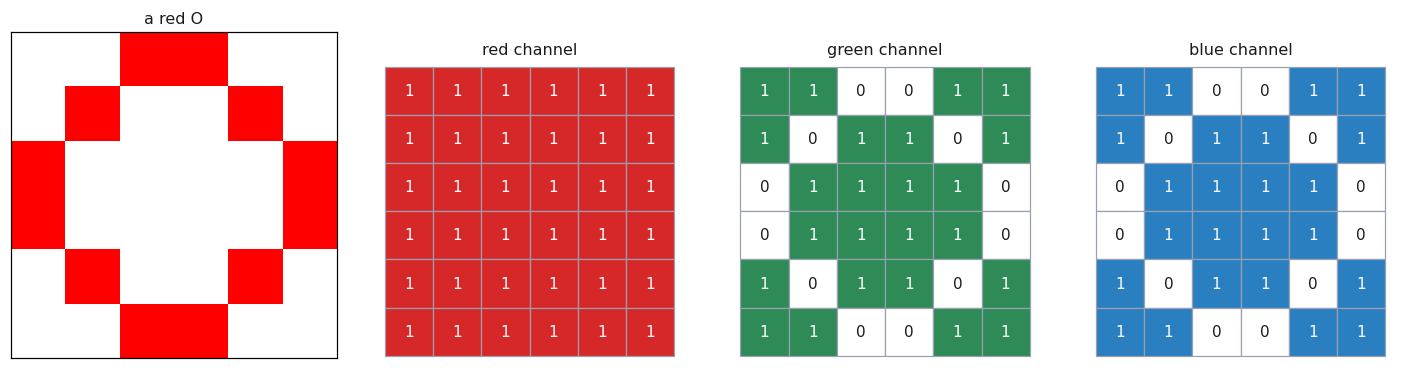

In [27]:
def color_drawing(img, rgb):
    # white background, the stroke painted in the given color
    out = np.ones(img.shape + (3,))
    for k in range(3):
        out[..., k] = np.where(img == 1, rgb[k], 1.0)
    return out

RED_O = color_drawing(IMG_O, (1, 0, 0))
fig, axes = plt.subplots(1, 4, figsize=(13.2, 3.9), dpi=110)
fig.patch.set_facecolor("white")
axes[0].imshow(RED_O, interpolation="nearest")
axes[0].set_xticks([]); axes[0].set_yticks([])
axes[0].set_title("a red O", fontsize=10.5, color=chh.INK)
for k, (ax, name, col) in enumerate(zip(axes[1:], ("red channel", "green channel", "blue channel"),
                                        ("#D62828", "#2E8B57", "#2A7FC1"))):
    ax.set_facecolor("white"); ax.axis("off"); ax.set_aspect("equal")
    ax.set_xlim(-0.2, 3.8); ax.set_ylim(-3.9, 0.7)
    grid(ax, RED_O[..., k], 0.0, 0.0, 0.6, kind="pixels", fs=10, shade=col, title=name, title_fs=10.5)
fig.tight_layout()

### A Color Filter Is Three Grids Too

- One 3 by 3 per channel: <b style="color:#73000A;">27 weights</b>, plus one bias
- Overlay all three at once, multiply, and add all 27 products: still one number, into one feature map
- Worked at the top left: the red channel's nine products add to 3, green's to 0, blue's to 0. Total <b style="color:#73000A;">3</b>

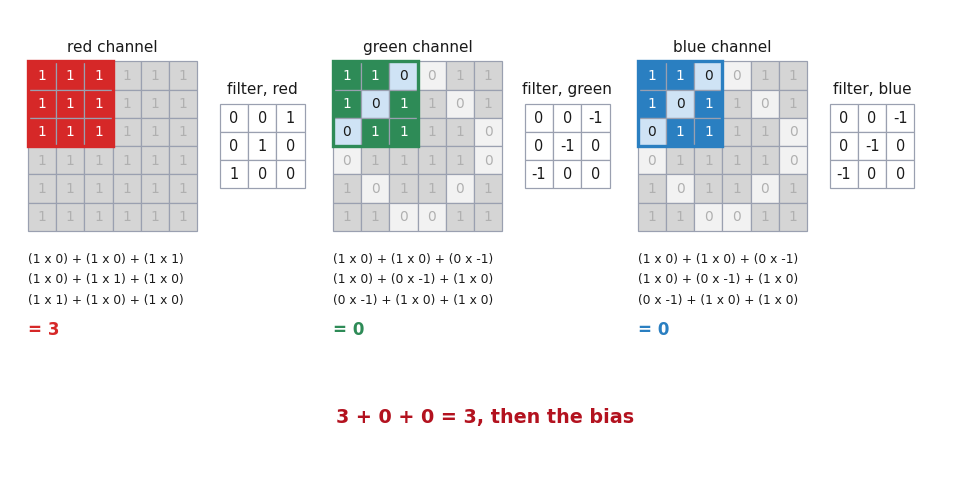

In [28]:
CFILTER = np.stack([FILTER, -FILTER, -FILTER]) + 0.0     # red grid, green grid, blue grid
fig, ax = frame((13.2, 5.4), (-0.3, 16.2), (-7.2, 0.9))
total = 0.0
for k, (name, col) in enumerate((("red", "#D62828"), ("green", "#2E8B57"), ("blue", "#2A7FC1"))):
    x = k * 5.4
    grid(ax, RED_O[..., k], x, 0.0, 0.5, kind="pixels", fs=9, shade=col, title=name + " channel",
         title_fs=10, window=(0, 0, 3, 3), window_color=col, dim_outside=True)
    grid(ax, CFILTER[k], x + 3.4, -0.75, 0.5, kind="numbers", fs=9.5, title="filter, " + name, title_fs=10)
    lines, s = products_text(RED_O[0:3, 0:3, k], CFILTER[k])
    for m, ln in enumerate(lines):
        note(ax, x, -3.5 - 0.36 * m, ln, fs=8)
    note(ax, x, -4.75, "= %g" % s, fs=11, color=col, weight="bold")
    total += s
note(ax, 8.1, -6.3, "3 + 0 + 0 = %g, then the bias" % total, fs=12.5, ha="center", color=chh.FITLINE, weight="bold")

### The Machine Again, in Color

- Three channels go in, three filter grids read them, and all 27 products land in <b style="color:#73000A;">one feature map</b>. Same bias of −2, same ReLU, same pooling, same four input network on the end
- The red grid adds 3 at every position. The green and blue grids subtract what is missing where the stroke is, so the map runs from −5 to 1
- After ReLU it is the map from the first half, so the four inputs and the answer are the ones from before: O <b style="color:#73000A;">1.00</b>, X 0.00

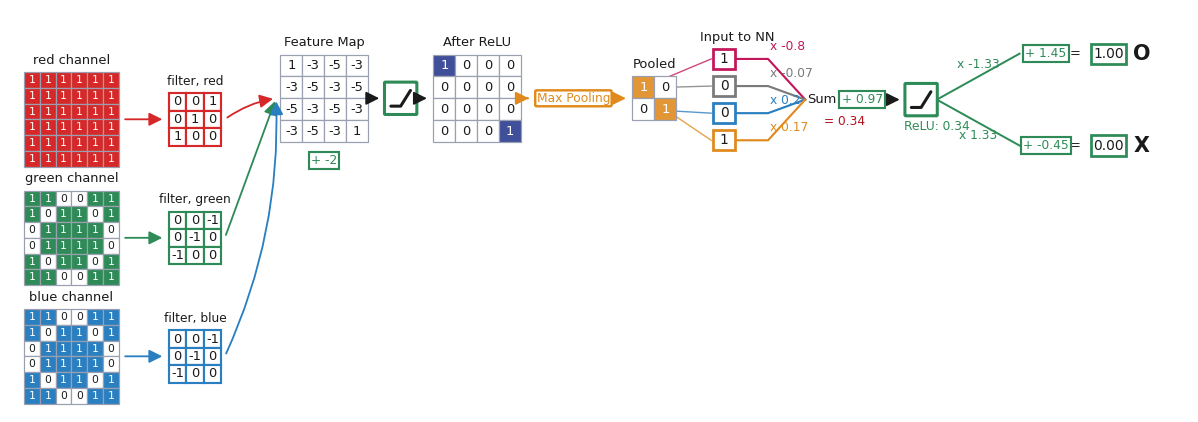

In [29]:
fig, ax = frame((13.8, 4.8), (-0.3, 26.6), (-8.15, 1.0))
_ = color_pipeline(ax, RED_O, CFILTER, cell=0.5)

### Why Keep the Color

- Turn the page gray, one number per pixel, and a red O and a blue O become <b style="color:#73000A;">the same drawing</b>. No filter can tell them apart after that

color filter at the top left:   red O +3    blue O -3
gray filter at the top left:    red O +2    blue O +2


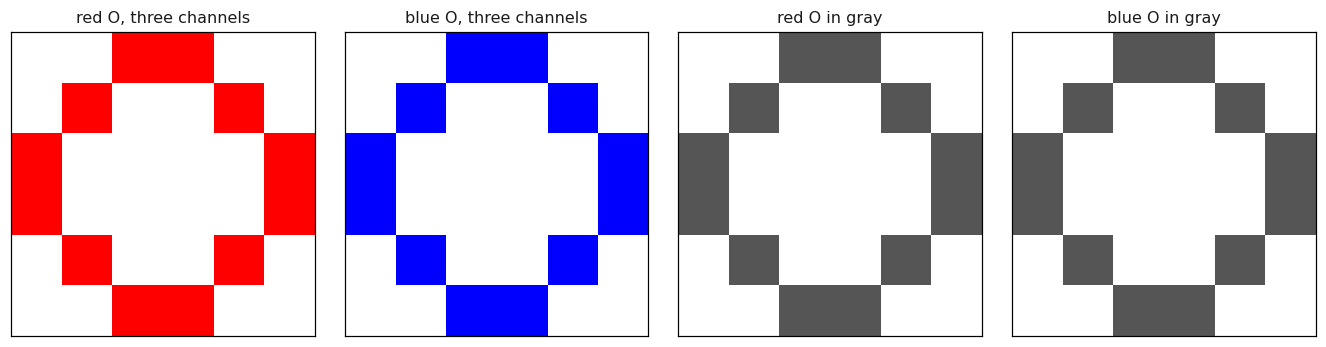

In [30]:
BLUE_O = color_drawing(IMG_O, (0, 0, 1))
def gray(rgb):
    return 1 - rgb.mean(axis=2)             # 1 is ink, 0 is page, as in the first half

def color_dot(rgb, cfilter, i=0, j=0):
    return sum(np.sum(rgb[i:i + 3, j:j + 3, k] * cfilter[k]) for k in range(3))

fig, axes = plt.subplots(1, 4, figsize=(12.4, 3.6), dpi=110)
fig.patch.set_facecolor("white")
for ax, pic, ttl in zip(axes, (RED_O, BLUE_O, gray(RED_O), gray(BLUE_O)),
                        ("red O, three channels", "blue O, three channels", "red O in gray", "blue O in gray")):
    if pic.ndim == 3:
        ax.imshow(pic, interpolation="nearest")
    else:
        ax.imshow(1 - pic, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(ttl, fontsize=10.5, color=chh.INK)
fig.tight_layout()
print("color filter at the top left:   red O %+g    blue O %+g" % (color_dot(RED_O, CFILTER), color_dot(BLUE_O, CFILTER)))
print("gray filter at the top left:    red O %+g    blue O %+g" % (np.sum(gray(RED_O)[0:3, 0:3] * FILTER),
                                                                    np.sum(gray(BLUE_O)[0:3, 0:3] * FILTER)))

### If color not needed...gray simplifies...

- When the data do not need color, gray is fine and it is <b style="color:#73000A;">a third of the calculations</b>.

### A Photo Has Channels Too

- Any color photo is three grids the size of the picture. A 600 by 512 photo is <b style="color:#73000A;">921,600 numbers...</b>
- The three channels of one photo, each shown in its own color

shape of the photo: (600, 512, 3)    numbers: 921600


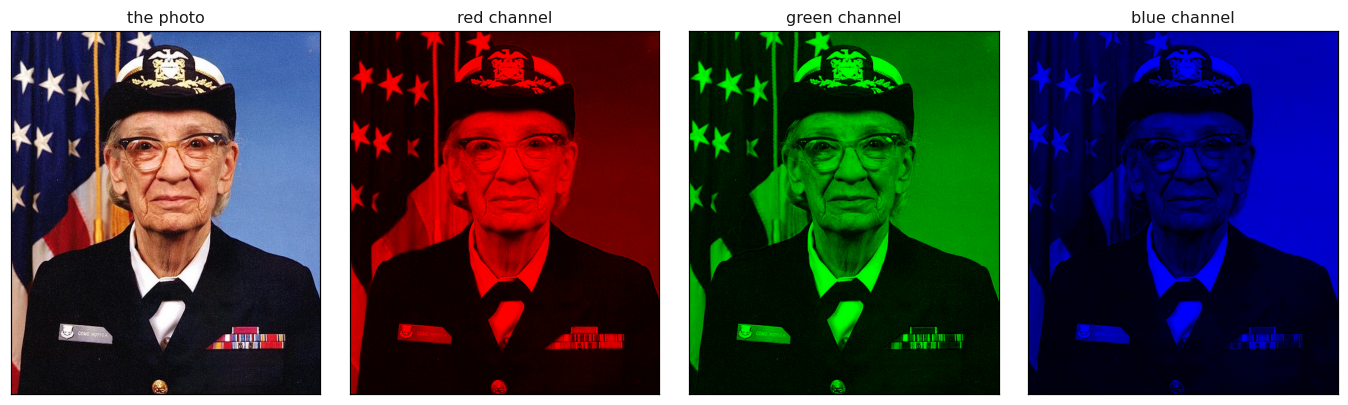

In [31]:
rgb = mpimg.imread(cbook.get_sample_data("grace_hopper.jpg", asfileobj=False)) / 255.0
fig, axes = plt.subplots(1, 4, figsize=(12.6, 3.9), dpi=110)
fig.patch.set_facecolor("white")
axes[0].imshow(rgb); axes[0].set_title("the photo", fontsize=10.5, color=chh.INK)
for k, (ax, name) in enumerate(zip(axes[1:], ("red channel", "green channel", "blue channel"))):
    only = np.zeros_like(rgb); only[..., k] = rgb[..., k]
    ax.imshow(only); ax.set_title(name, fontsize=10.5, color=chh.INK)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()
print("shape of the photo:", rgb.shape, "   numbers:", rgb.size)

### In PyTorch: in_channels=3

- `nn.Conv2d(in_channels=3, out_channels=1, kernel_size=3)`: the weight tensor is 1 filter by 3 channels by 3 by 3, the 27 numbers from two slides ago
- `out_channels` is how many filters. Each filter makes one feature map, and that count is the <b style="color:#73000A;">next layer's in_channels</b>
- A color picture goes in with shape (batch, 3, rows, columns)

In [32]:
conv3 = nn.Conv2d(in_channels=3, out_channels=1, kernel_size=3)
with torch.no_grad():
    conv3.weight[:] = torch.tensor(CFILTER, dtype=torch.float32)
    conv3.bias[:] = 0.0
    for name, pic in (("red O", RED_O), ("blue O", BLUE_O)):
        x = torch.tensor(pic, dtype=torch.float32).permute(2, 0, 1).unsqueeze(0)   # (1, 3, 6, 6)
        fmap = conv3(x)[0, 0]
        print("%-8s input shape %s   feature map top left %+g   whole map min %+g max %+g"
              % (name, tuple(x.shape), fmap[0, 0].item(), fmap.min().item(), fmap.max().item()))
print("weight shape:", tuple(conv3.weight.shape), "  weights:", conv3.weight.numel(), " bias:", conv3.bias.numel())

red O    input shape (1, 3, 6, 6)   feature map top left +3   whole map min -3 max +3
blue O   input shape (1, 3, 6, 6)   feature map top left -3   whole map min -3 max -3
weight shape: (1, 3, 3, 3)   weights: 27  bias: 1


## CNN Example: Handwritten Digits Off Old Forms

- Census pages, tax rolls and ledgers were filled in by hand. Turning them into data means reading digits off scans, millions of them
- The standard training set: <b style="color:#73000A;">70,000 scanned digits</b>, each 28 by 28 pixels, each labeled 0 to 9
- A pixel is now a <b style="color:#73000A;">gray level from 0 to 1</b>, not just 0 or 1. The filter arithmetic does not care

training on 10000 digits, testing on 2000


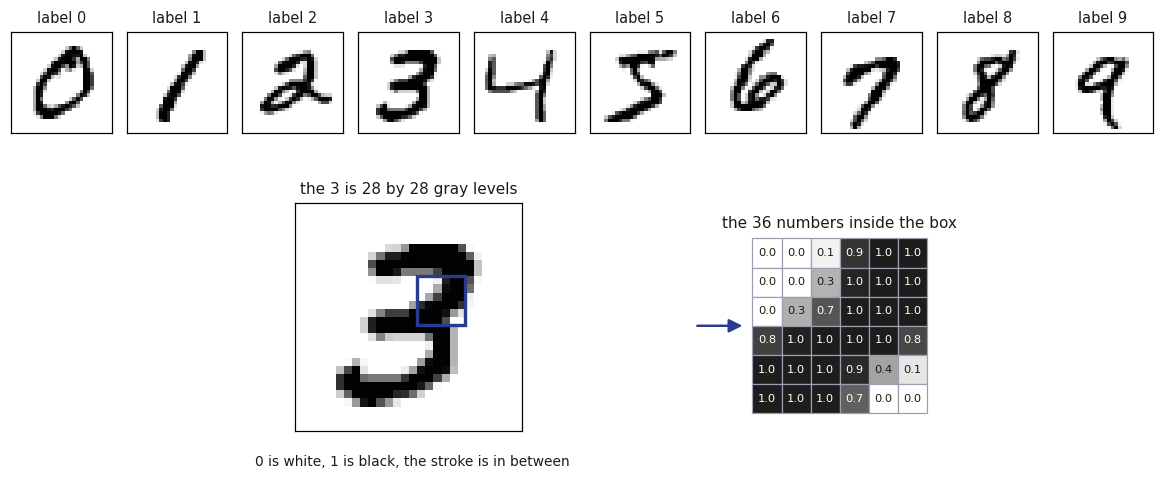

In [33]:
import gzip, shutil, pathlib
from torchvision import datasets
for packed in pathlib.Path("data/MNIST/raw").glob("*.gz"):   # the repo ships the packed files
    if not packed.with_suffix("").exists():
        with gzip.open(packed) as src, open(packed.with_suffix(""), "wb") as dst:
            shutil.copyfileobj(src, dst)
train_set = datasets.MNIST("data", train=True, download=False)
test_set = datasets.MNIST("data", train=False, download=False)
Xtr = train_set.data[:10000].unsqueeze(1).float() / 255.0     # (10000, 1, 28, 28)
ytr = train_set.targets[:10000]
Xte = test_set.data[:2000].unsqueeze(1).float() / 255.0
yte = test_set.targets[:2000]
fig = plt.figure(figsize=(13.4, 4.9), dpi=110)
fig.patch.set_facecolor("white")
gs = fig.add_gridspec(2, 10, height_ratios=[1.0, 1.7], hspace=0.3, wspace=0.15)
for d in range(10):
    ax = fig.add_subplot(gs[0, d])
    k = int((ytr == d).nonzero()[0])
    ax.imshow(Xtr[k, 0], cmap="gray_r", vmin=0, vmax=1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title("label %d" % d, fontsize=9.5, color=chh.INK)
# the 3 again, larger, with a 6 by 6 box drawn on it, and the numbers inside that box
k = int((ytr == 3).nonzero()[0])
r0, c0 = 9, 15
ax = fig.add_subplot(gs[1, 2:5])
ax.imshow(Xtr[k, 0], cmap="gray_r", vmin=0, vmax=1)
ax.add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), 6, 6, fill=False, edgecolor=chh.MADRID, lw=2.2))
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("the 3 is 28 by 28 gray levels", fontsize=10, color=chh.INK)
ax.text(14, 30.5, "0 is white, 1 is black, the stroke is in between", ha="center", va="top", fontsize=9, color=chh.INK)
ax = fig.add_subplot(gs[1, 5:9])
ax.set_facecolor("white"); ax.axis("off"); ax.set_aspect("equal")
ax.set_xlim(-1.1, 3.2); ax.set_ylim(-3.3, 0.6)
grid(ax, Xtr[k, 0, r0:r0 + 6, c0:c0 + 6].numpy(), 0.0, 0.0, 0.5, kind="pixels", fs=7.5, fmt="%.1f",
     shade="#1A1A1A", title="the 36 numbers inside the box", title_fs=10)
arrow(ax, (-1.0, -1.5), (-0.12, -1.5), color=chh.MADRID, lw=1.6)
print("training on", len(Xtr), "digits, testing on", len(Xte))

### Four Filters

- `nn.Conv2d(1, 4, 3)`: four 3 by 3 filters and four biases, <b style="color:#73000A;">40 numbers</b>. Four 26 by 26 feature maps
- ReLU, then 2 by 2 max pooling: four 13 by 13 maps, <b style="color:#73000A;">676 numbers</b>
- `nn.Linear(676, 10)`: ten raw outputs, SoftMax and cross entropy
- 6,810 parameters in all. A dense first layer with 676 hidden nodes on the 784 pixels would need 530,660

In [34]:
class DigitCNN(nn.Module):
    def __init__(self, filters=4):
        super().__init__()
        self.conv = nn.Conv2d(1, filters, kernel_size=3)
        self.pool = nn.MaxPool2d(2, 2)
        self.out = nn.Linear(filters * 13 * 13, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv(x)))
        return self.out(x.flatten(1))

digits = DigitCNN()
print("parameters:", sum(p.numel() for p in digits.parameters()))
print("a dense layer, 784 pixels to 676 hidden nodes:", 784 * 676 + 676)

# train it: five passes over the 10,000 digits, fifty at a time
torch.manual_seed(0)
digits = DigitCNN()
opt = torch.optim.Adam(digits.parameters(), lr=0.003)
for epoch in range(5):
    order = torch.randperm(len(Xtr))
    for b in range(0, len(Xtr), 50):
        idx = order[b:b + 50]
        opt.zero_grad()
        loss = F.cross_entropy(digits(Xtr[idx]), ytr[idx])
        loss.backward()
        opt.step()
    with torch.no_grad():
        pred = digits(Xte).argmax(dim=1)
    print("pass %d   held back digits read correctly: %.1f%%" % (epoch + 1, 100 * (pred == yte).float().mean()))


parameters: 6810
a dense layer, 784 pixels to 676 hidden nodes: 530660
pass 1   held back digits read correctly: 87.4%
pass 2   held back digits read correctly: 90.1%
pass 3   held back digits read correctly: 90.3%
pass 4   held back digits read correctly: 91.5%
pass 5   held back digits read correctly: 91.2%


### Reading `nn.Conv2d(1, 4, 3)`

The three numbers have names. Written out in full the same line is

`nn.Conv2d(in_channels=1, out_channels=4, kernel_size=3)`

- <b style="color:#B3121F;">in_channels=1</b>: how many grids each picture has. A gray digit has one; a color photo has three
- <b style="color:#2E8B57;">out_channels=4</b>: how many filters to learn. Each filter makes its own feature map, so four maps come out
- <b style="color:#2A3B8F;">kernel_size=3</b>: each filter is 3 by 3, the size of the window that slides

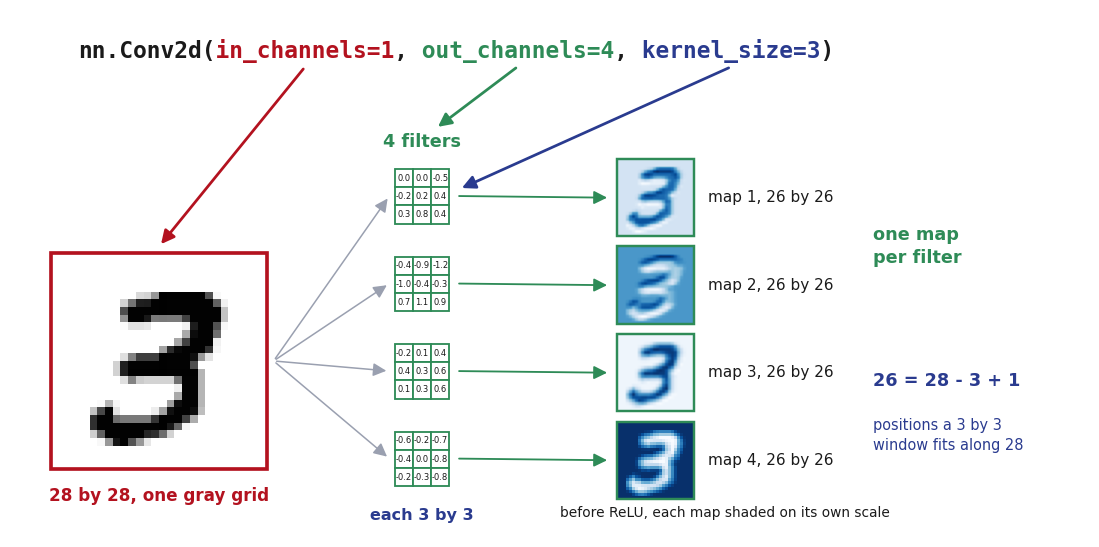

In [35]:
def code_line(ax, x, y, pieces, fs=15):
    """Draw text pieces left to right in their own colours; returns the
       centre bottom of each piece, so arrows can start from it. Each piece is
       padded with spaces for everything before it, so a monospace font lines
       them up without any measuring."""
    texts, before = [], 0
    for text, color in pieces:
        t = ax.text(x, y, " " * before + text, fontsize=fs, family="monospace",
                    va="center", ha="left", color=color, weight="bold", zorder=8)
        texts.append((t, before, len(text)))
        before += len(text)
    ax.figure.canvas.draw()
    anchors = []
    for t, b, n in texts:
        bb = t.get_window_extent().transformed(ax.transData.inverted())
        step = (bb.x1 - bb.x0) / (b + n)
        anchors.append((bb.x0 + step * (b + n / 2), bb.y0))
    return anchors


IN_C, OUT_C, K_C = "#B3121F", RELU_GREEN, chh.MADRID
k3 = int((ytr == 3).nonzero()[0])
w = digits.conv.weight.detach()[:, 0].numpy()
with torch.no_grad():
    fmaps = digits.conv(Xtr[k3:k3 + 1])[0].numpy()

fig, ax = frame((13.4, 6.2), (-0.4, 15.6), (-6.6, 1.2))
a = code_line(ax, 0.6, 0.6, [("nn.Conv2d(", chh.INK), ("in_channels=1", IN_C), (", ", chh.INK),
                             ("out_channels=4", OUT_C), (", ", chh.INK),
                             ("kernel_size=3", K_C), (")", chh.INK)])

# the picture: one gray channel
ax.imshow(Xtr[k3, 0], cmap="gray_r", vmin=0, vmax=1, extent=(0.2, 3.4, -5.6, -2.4), zorder=3)
ax.add_patch(plt.Rectangle((0.2, -5.6), 3.2, 3.2, fill=False, edgecolor=IN_C, lw=2.4, zorder=4))
note(ax, 1.8, -6.0, "28 by 28, one gray grid", fs=11, ha="center", color=IN_C, weight="bold")
arrow(ax, (a[1][0], a[1][1] - 0.05), (1.8, -2.3), color=IN_C, lw=1.8)

# the four filters, each 3 by 3
fx, cell = 5.3, 0.27
tops = [-1.55, -2.85, -4.15, -5.45]
for f, top in enumerate(tops):
    grid(ax, np.round(w[f], 1) + 0.0, fx, top + 0.4, cell, kind="numbers", fs=5.5, fmt="%.1f", edge=OUT_C, lw=1.2)
note(ax, fx + 1.5 * cell, -0.75, "4 filters", fs=11.5, ha="center", color=OUT_C, weight="bold")
arrow(ax, (a[3][0], a[3][1] - 0.05), (fx + 1.5 * cell + 0.2, -0.55), color=OUT_C, lw=1.8)
note(ax, fx + 1.5 * cell, tops[3] - 0.85, "each 3 by 3", fs=10.5, ha="center", color=K_C, weight="bold")
ax.annotate("", xy=(fx + 1.5 * cell + 0.55, tops[0] + 0.1), xytext=(a[5][0], a[5][1] - 0.05),
            arrowprops=dict(arrowstyle="-|>", color=K_C, lw=1.8, shrinkA=2, shrinkB=2), zorder=6)
for top in tops:
    arrow(ax, (3.5, -4.0), (fx - 0.08, top - 0.0), color="#9AA0B0", lw=1.0)

# the four feature maps
mx, size = 8.6, 1.15
for f, top in enumerate(tops):
    y0 = top + 0.55
    ax.imshow(fmaps[f], cmap="Blues", extent=(mx, mx + size, y0 - size, y0), zorder=3)
    ax.add_patch(plt.Rectangle((mx, y0 - size), size, size, fill=False, edgecolor=OUT_C, lw=1.6, zorder=4))
    arrow(ax, (fx + 3 * cell + 0.1, top), (mx - 0.1, y0 - size / 2), color=OUT_C, lw=1.2)
    note(ax, mx + size + 0.2, y0 - size / 2, "map %d, 26 by 26" % (f + 1), fs=10, color=chh.INK)
note(ax, mx + 1.6, -6.25, "before ReLU, each map shaded on its own scale", fs=9, ha="center", color=chh.INK)
note(ax, 12.4, -2.3, "one map\nper filter", fs=11.5, ha="left", color=OUT_C, weight="bold")
note(ax, 12.4, -4.3, "26 = 28 - 3 + 1", fs=11.5, ha="left", color=K_C, weight="bold")
note(ax, 12.4, -4.85, "positions a 3 by 3\nwindow fits along 28", fs=9.5, ha="left", va="top", color=K_C)

### Where the Four Channels Come From

A <b style="color:#73000A;">channel</b> is one grid of numbers. Channels going in come with the data; channels coming out are made by the filters, one per filter.

| layer | channels in | each filter is | channels out |
|---|---|---|---|
| the red O, earlier | 3, red green blue, from the photo | three 3 by 3 grids, added into one map | 1 |
| this layer | 1, the gray digit | one 3 by 3 grid | <b style="color:#2E8B57;">4, one per filter</b> |
| the second round, next | 8, made by the first round | eight 3 by 3 grids | 16 |

Whatever one layer makes, the next layer reads as its channels.

### How One Map Is Made

The same arithmetic as the O: put filter 1 on the 3, multiply the nine pixels by the nine weights, add them up, add the bias. That is <b style="color:#73000A;">one cell</b> of map 1.

Slide one pixel and do it again: 26 positions across times 26 down is the whole map. The blue picture is that grid of numbers, darker where the number is bigger.

 - We could have used any color, not just Blue...

by hand 1.9843    nn.Conv2d says 1.9843


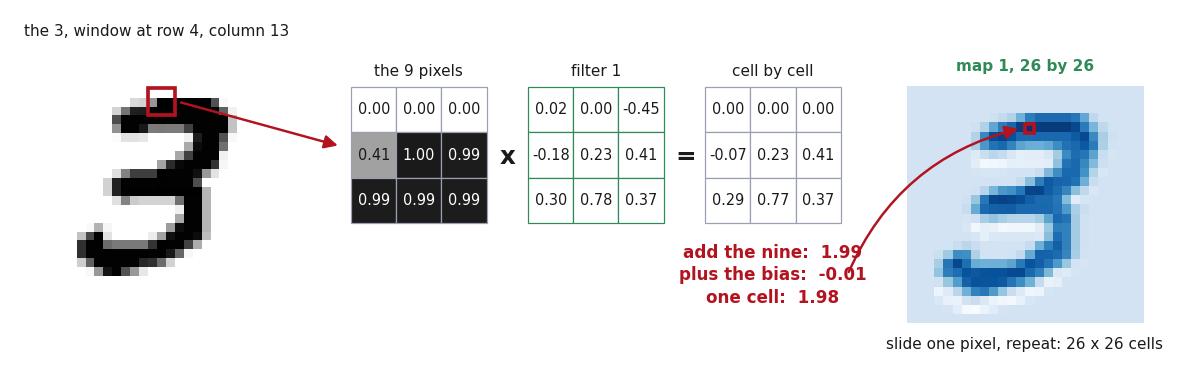

In [36]:
b1 = float(digits.conv.bias.detach()[0])
m1 = fmaps[0]
r, c = np.unravel_index(np.argmax(m1), m1.shape)       # where filter 1 matched best
patch = Xtr[k3, 0, r:r + 3, c:c + 3].numpy()
prod = patch * w[0]
show = lambda M: np.round(M, 2) + 0.0      # no -0.00 on the slide
value = prod.sum() + b1

fig, ax = frame((13.6, 4.9), (-0.3, 16.4), (-5.5, -0.4))
s = 3.6 / 28
ax.imshow(Xtr[k3, 0], cmap="gray_r", vmin=0, vmax=1, extent=(0, 3.6, -4.6, -1.0), zorder=3)
ax.add_patch(plt.Rectangle((c * s, -1.0 - (r + 3) * s), 3 * s, 3 * s, fill=False,
                           edgecolor=chh.FITLINE, lw=2.4, zorder=5))
note(ax, 1.8, -0.7, "the 3, window at row %d, column %d" % (r, c), fs=10, ha="center")
arrow(ax, (c * s + 3 * s + 0.05, -1.0 - (r + 1.5) * s), (4.45, -2.35), color=chh.FITLINE, lw=1.6)

cell = 0.65
grid(ax, show(patch), 4.6, -1.5, cell, kind="pixels", fs=9.5, fmt="%.2f", shade="#1A1A1A",
     title="the 9 pixels", title_fs=10)
note(ax, 6.85, -2.5, "x", fs=16, ha="center", weight="bold")
grid(ax, show(w[0]), 7.15, -1.5, cell, kind="numbers", fs=9.5, fmt="%.2f", edge=RELU_GREEN,
     title="filter 1", title_fs=10)
note(ax, 9.42, -2.5, "=", fs=16, ha="center", weight="bold")
grid(ax, show(prod), 9.7, -1.5, cell, kind="numbers", fs=9.5, fmt="%.2f",
     title="cell by cell", title_fs=10)
note(ax, 10.67, -3.75, "add the nine:  %.2f\nplus the bias:  %+.2f\none cell:  %.2f"
     % (prod.sum(), b1, value), fs=11, ha="center", va="top", color=chh.FITLINE, weight="bold")

mx, size = 12.6, 3.4
ax.imshow(m1, cmap="Blues", extent=(mx, mx + size, -1.5 - size, -1.5), zorder=3)
cs = size / 26
ax.add_patch(plt.Rectangle((mx + c * cs, -1.5 - (r + 1) * cs), cs, cs, fill=False,
                           edgecolor=chh.FITLINE, lw=2.4, zorder=5))
note(ax, mx + size / 2, -1.2, "map 1, 26 by 26", fs=10, ha="center", color=RELU_GREEN, weight="bold")
arrow(ax, (11.75, -4.2), (mx + c * cs - 0.05, -1.5 - (r + 0.5) * cs), color=chh.FITLINE, lw=1.6, rad=-0.25)
note(ax, mx + size / 2, -5.2, "slide one pixel, repeat: 26 x 26 cells", fs=10, ha="center")
print("by hand %.4f    nn.Conv2d says %.4f" % (value, m1[r, c]))

### Reading `nn.MaxPool2d(2, 2)`

`nn.MaxPool2d(kernel_size=2, stride=2)`

- <b style="color:#2A3B8F;">kernel_size=2</b>: look at one 2 by 2 block at a time and keep its largest number
- <b style="color:#E08A1E;">stride=2</b>: jump two cells to the next block, so the blocks never overlap
- 26 by 26 becomes <b style="color:#73000A;">13 by 13</b>. Pooling has no weights at all; nothing in it is learned

**Why not other strides?**

Arguments For:
- <b style="color:#E08A1E;">stride=1</b>: the blocks overlap, almost every cell is counted twice, and the map barely shrinks, 26 to <b style="color:#73000A;">25</b>
- <b style="color:#E08A1E;">stride=3</b>: the blocks leave gaps, those cells are never looked at, 26 to <b style="color:#73000A;">9</b>

But...
- Other choices do happen. AlexNet (2012) pooled 3 by 3 blocks with stride 2, a slight overlap, and it cut the error a little. Many newer networks drop pooling and shrink with a stride 2 convolution instead, so the shrinking is learned


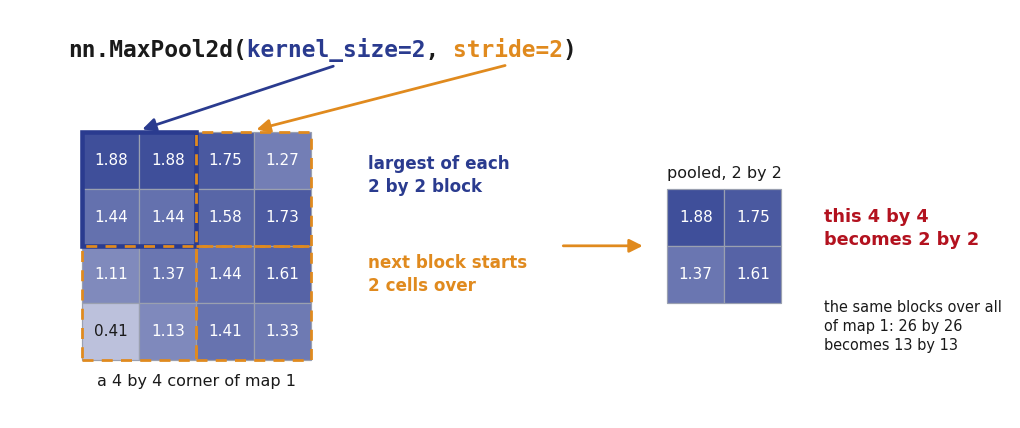

In [37]:
with torch.no_grad():
    post = F.relu(digits.conv(Xtr[k3:k3 + 1]))[0, 0].numpy()
# the 4 by 4 corner of map 1 with the most going on in it
best = max(((i, j) for i in range(0, 22, 2) for j in range(0, 22, 2)),
           key=lambda ij: (post[ij[0]:ij[0] + 4, ij[1]:ij[1] + 4] > 0).sum())
blk = post[best[0]:best[0] + 4, best[1]:best[1] + 4]
pooled = max_pool(blk)

fig, ax = frame((12.4, 4.8), (-0.4, 13.6), (-4.4, 1.3))
a = code_line(ax, 0.4, 0.75, [("nn.MaxPool2d(", chh.INK), ("kernel_size=2", K_C), (", ", chh.INK),
                              ("stride=2", POOL), (")", chh.INK)])
cell = 0.8
grid(ax, blk, 0.6, -0.4, cell, kind="numbers", fs=10, fmt="%.2f", shade=MAPFILL)
note(ax, 0.6 + 2 * cell, -0.4 - 4 * cell - 0.3, "a 4 by 4 corner of map 1", fs=10.5, ha="center")
blocks = [(0, 0), (0, 2), (2, 0), (2, 2)]
cols = [K_C, POOL, POOL, POOL]
for (i, j), col in zip(blocks, cols):
    ax.add_patch(plt.Rectangle((0.6 + j * cell, -0.4 - (i + 2) * cell), 2 * cell, 2 * cell, fill=False,
                               edgecolor=col, lw=3.0 if col == K_C else 1.8,
                               ls="-" if col == K_C else (0, (4, 3)), zorder=6))
arrow(ax, (a[1][0], a[1][1] - 0.05), (0.6 + cell, -0.38), color=K_C, lw=1.8)
arrow(ax, (a[3][0], a[3][1] - 0.05), (0.6 + 3 * cell, -0.38), color=POOL, lw=1.8)
note(ax, 4.6, -1.0, "largest of each\n2 by 2 block", fs=11, ha="left", color=K_C, weight="bold")
note(ax, 4.6, -2.4, "next block starts\n2 cells over", fs=11, ha="left", color=POOL, weight="bold")
arrow(ax, (7.3, -2.0), (8.5, -2.0), lw=1.8, color=POOL)
grid(ax, pooled, 8.8, -1.2, cell, kind="numbers", fs=10, fmt="%.2f", shade=MAPFILL,
     title="pooled, 2 by 2", title_fs=10.5)
note(ax, 11.0, -1.75, "this 4 by 4\nbecomes 2 by 2", fs=11.5, ha="left",
     color=chh.FITLINE, weight="bold")
note(ax, 11.0, -2.75, "the same blocks over all\nof map 1: 26 by 26\nbecomes 13 by 13", fs=9.5,
     ha="left", va="top", color=chh.INK)

### Reading `nn.Linear(676, 10)`

`nn.Linear(in_features=676, out_features=10)`

- <b style="color:#B3121F;">in_features=676</b>: the four pooled 13 by 13 maps laid end to end, $4 \times 13 \times 13 = 676$. This number has to match what comes in, or PyTorch stops with an error
- <b style="color:#2E8B57;">out_features=10</b>: one raw output per digit, 0 to 9, then SoftMax and cross entropy from lecture 12
- Econometrics: ten linear indexes, each with <b style="color:#73000A;">676 coefficients and an intercept</b>, fed into a multinomial logit.

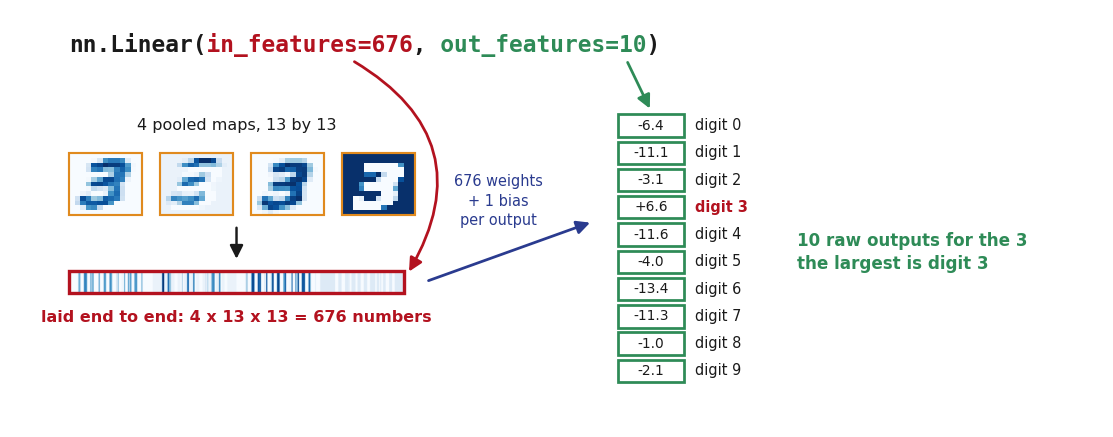

In [38]:
fig, ax = frame((12.8, 4.9), (-0.4, 14.6), (-5.4, 1.3))
a = code_line(ax, 0.4, 0.75, [("nn.Linear(", chh.INK), ("in_features=676", IN_C), (", ", chh.INK),
                              ("out_features=10", OUT_C), (")", chh.INK)])
with torch.no_grad():
    pooled_maps = digits.pool(F.relu(digits.conv(Xtr[k3:k3 + 1])))[0].numpy()
    raw = digits(Xtr[k3:k3 + 1])[0].numpy()
# four pooled maps, then laid end to end
for f in range(4):
    x0 = 0.4 + f * 1.25
    ax.imshow(pooled_maps[f], cmap="Blues", extent=(x0, x0 + 1.0, -2.0, -1.0), zorder=3)
    ax.add_patch(plt.Rectangle((x0, -2.0), 1.0, 1.0, fill=False, edgecolor=POOL, lw=1.4, zorder=4))
note(ax, 2.7, -0.55, "4 pooled maps, 13 by 13", fs=10.5, ha="center", color=chh.INK)
arrow(ax, (2.7, -2.15), (2.7, -2.75), lw=1.6)
col = pooled_maps.reshape(-1)
ax.imshow(col[None, :], cmap="Blues", aspect="auto", extent=(0.4, 5.0, -3.25, -2.9), zorder=3)
ax.add_patch(plt.Rectangle((0.4, -3.25), 4.6, 0.35, fill=False, edgecolor=IN_C, lw=2.2, zorder=4))
note(ax, 2.7, -3.65, "laid end to end: 4 x 13 x 13 = 676 numbers", fs=10.5, ha="center",
     color=IN_C, weight="bold")
arrow(ax, (a[1][0], a[1][1] - 0.05), (5.05, -2.95), color=IN_C, lw=1.8, rad=-0.5)
# the ten outputs
arrow(ax, (5.3, -3.07), (7.6, -2.1), color=chh.MADRID, lw=1.8)
note(ax, 6.3, -2.2, "676 weights\n+ 1 bias\nper output", fs=9.5, ha="center", va="bottom", color=chh.MADRID)
for d in range(10):
    y = -0.55 - d * 0.44
    value_box(ax, 8.4, y, "%+.1f" % raw[d], OUT_C, fs=9, w=0.9, h=0.36)
    note(ax, 9.0, y, "digit %d" % d, fs=9.5, color=chh.FITLINE if d == raw.argmax() else chh.INK,
         weight="bold" if d == raw.argmax() else None)
arrow(ax, (a[3][0], a[3][1] - 0.05), (8.4, -0.32), color=OUT_C, lw=1.8)
note(ax, 10.4, -2.6, "10 raw outputs for the 3\nthe largest is digit %d" % raw.argmax(), fs=11,
     ha="left", color=OUT_C, weight="bold")

### One Digit Through the Network

Pass the 3 through one step at a time and print its shape after each. The shape reads (pictures, grids, rows, columns).

In [39]:
x = Xtr[k3:k3 + 1]
steps = [("the picture", x, "1 picture, in_channels=1, 28 by 28")]
with torch.no_grad():
    x = digits.conv(x);  steps.append(("Conv2d", x, "out_channels=4 maps, 28 - kernel_size + 1 = 26"))
    x = F.relu(x);       steps.append(("ReLU", x, "same shape, negatives set to 0"))
    x = digits.pool(x);  steps.append(("MaxPool2d", x, "26 / stride 2 = 13"))
    x = x.flatten(1);    steps.append(("flatten", x, "4 x 13 x 13 = 676 = in_features"))
    x = digits.out(x);   steps.append(("Linear", x, "out_features=10, one per digit"))
for name, t, why in steps:
    print("%-12s %-20s %s" % (name, str(tuple(t.shape)), why))

print()
print("%-14s %-16s %8s" % ("parameter", "shape", "count"))
for name, p in digits.named_parameters():
    print("%-14s %-16s %8s" % (name, str(tuple(p.shape)), format(p.numel(), ",")))
print("%-14s %-16s %8s" % ("total", "", format(sum(p.numel() for p in digits.parameters()), ",")))

the picture  (1, 1, 28, 28)       1 picture, in_channels=1, 28 by 28
Conv2d       (1, 4, 26, 26)       out_channels=4 maps, 28 - kernel_size + 1 = 26
ReLU         (1, 4, 26, 26)       same shape, negatives set to 0
MaxPool2d    (1, 4, 13, 13)       26 / stride 2 = 13
flatten      (1, 676)             4 x 13 x 13 = 676 = in_features
Linear       (1, 10)              out_features=10, one per digit

parameter      shape               count
conv.weight    (4, 1, 3, 3)           36
conv.bias      (4,)                    4
out.weight     (10, 676)           6,760
out.bias       (10,)                  10
total                              6,810


### Parameter Breakdown

- `conv.weight` is (out_channels, in_channels, 3, 3) = (4, 1, 3, 3): <b style="color:#73000A;">36 numbers</b>, the four filters
- `conv.bias`: one per filter, <b style="color:#73000A;">4</b>
- `out.weight` is (out_features, in_features) = (10, 676): <b style="color:#73000A;">6,760</b>, almost all of the model
- `out.bias`: one per digit, <b style="color:#73000A;">10</b>

The filters are 40 of the 6,810 numbers. The dense layer at the end is the expensive part, which is why a second round of pooling helps.

### The Four Filters It Learned

- Backpropagation found four 3 by 3 patterns that help tell the ten digits apart
- Below each filter, its feature map for one 3: where in the drawing that pattern was found

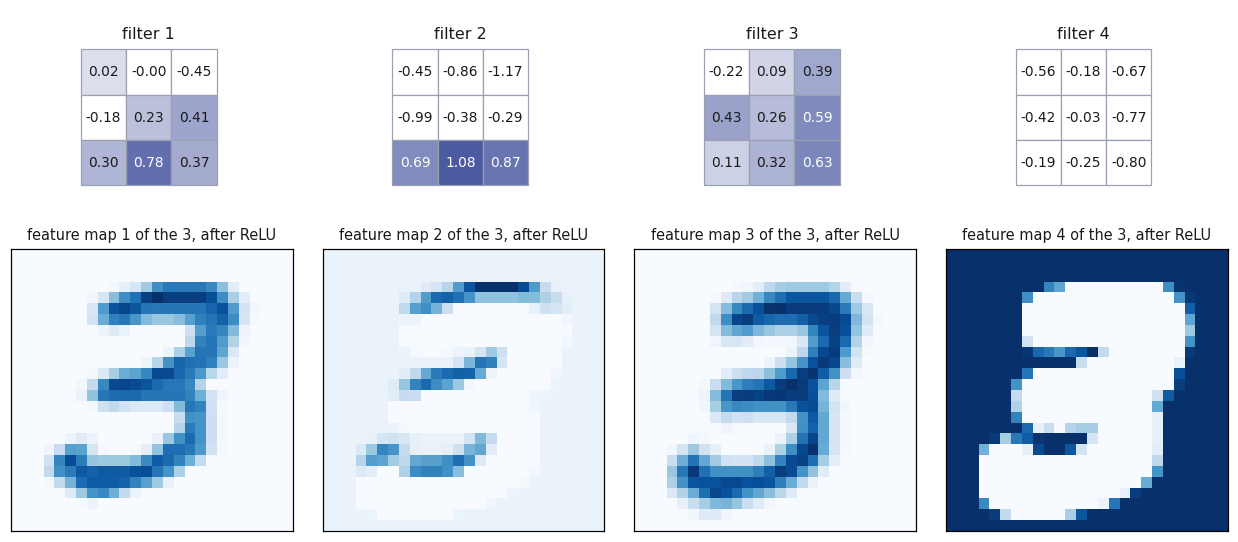

In [40]:
filters = digits.conv.weight.detach()[:, 0].numpy()
k = int((ytr == 3).nonzero()[0])
with torch.no_grad():
    maps = F.relu(digits.conv(Xtr[k:k + 1]))[0].numpy()
fig, axes = plt.subplots(2, 4, figsize=(11.6, 5.4), dpi=110, gridspec_kw={"height_ratios": [1, 1.6]})
fig.patch.set_facecolor("white")
for f in range(4):
    ax = axes[0, f]
    ax.set_facecolor("white"); ax.axis("off"); ax.set_aspect("equal")
    ax.set_xlim(-0.4, 2.6); ax.set_ylim(-2.4, 0.6)
    grid(ax, filters[f], 0.0, 0.0, 0.7, kind="numbers", fs=9, fmt="%.2f", shade=MAPFILL,
         title="filter %d" % (f + 1), title_fs=10.5)
    axes[1, f].imshow(maps[f], cmap="Blues")
    axes[1, f].set_xticks([]); axes[1, f].set_yticks([])
    axes[1, f].set_title("feature map %d of the 3, after ReLU" % (f + 1), fontsize=9.5, color=chh.INK)
fig.tight_layout()

### Incorrect Predictions

- The first ten held back digits it misread, with what it said and what was written
- Most are the ones a person would hesitate over too.

misread 176 of 2000


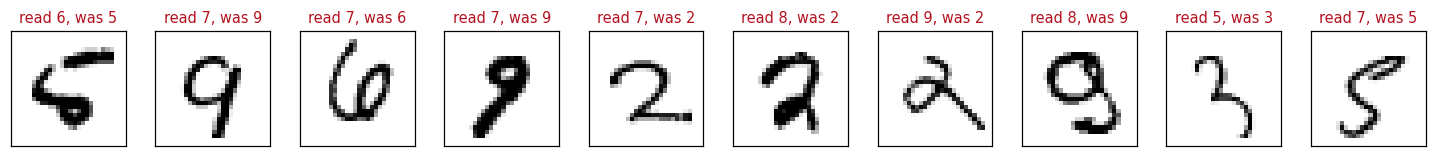

In [41]:
with torch.no_grad():
    pred = digits(Xte).argmax(dim=1)
wrong = (pred != yte).nonzero().flatten()[:10]
fig, axes = plt.subplots(1, 10, figsize=(13.4, 2.1), dpi=110)
fig.patch.set_facecolor("white")
for ax, i in zip(axes, wrong):
    ax.imshow(Xte[i, 0], cmap="gray_r", vmin=0, vmax=1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title("read %d, was %d" % (pred[i], yte[i]), fontsize=9.5, color=chh.FITLINE)
fig.tight_layout()
print("misread %d of %d" % ((pred != yte).sum(), len(yte)))

### A Second Round

- The four 13 by 13 maps are a picture with four channels. So run <b style="color:#73000A;">another set of filters</b> over them, each filter 3 by 3 by 4, then ReLU and pooling again
- Eight filters, then sixteen: the picture shrinks to 5 by 5 by 16, 400 numbers into the last layer. <b style="color:#73000A;">5,258 parameters</b>, fewer than the one round version, since the dense layer got smaller
- Trained the same way on the same digits, eight passes. With all 60,000 and more passes this design reads above 99 percent

parameters: 5258
pass 1   held back digits read correctly: 89.9%
pass 2   held back digits read correctly: 94.7%
pass 3   held back digits read correctly: 94.8%
pass 4   held back digits read correctly: 96.2%
pass 5   held back digits read correctly: 96.0%
pass 6   held back digits read correctly: 96.0%
pass 7   held back digits read correctly: 96.5%
pass 8   held back digits read correctly: 96.0%


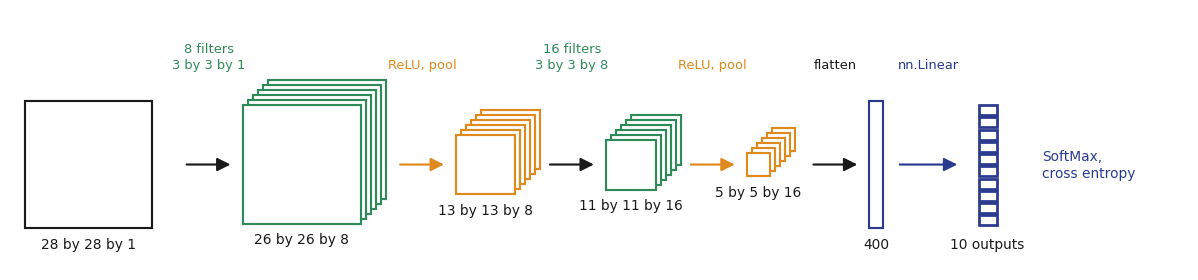

In [42]:
fig, ax = frame((13.8, 3.9), (-0.3, 25.6), (-2.3, 3.4))

def stack(ax, x, y, w, h, n, label, color, gap=0.11):
    # n sheets of size w by h, stepped back and up, labelled under the front one
    for k in range(min(n, 6) - 1, -1, -1):
        ax.add_patch(plt.Rectangle((x + k * gap, y + k * gap), w, h, facecolor="white",
                                   edgecolor=color, lw=1.4, zorder=3 + (6 - k)))
    note(ax, x + w / 2, y - 0.35, label, fs=9, ha="center")

stack(ax, 0.0, -1.4, 2.8, 2.8, 1, "28 by 28 by 1", chh.INK)
arrow(ax, (3.5, 0.0), (4.6, 0.0), lw=1.4)
note(ax, 4.05, 2.05, "8 filters\n3 by 3 by 1", fs=8.5, ha="center", va="bottom", color=RELU_GREEN)
stack(ax, 4.8, -1.3, 2.6, 2.6, 8, "26 by 26 by 8", RELU_GREEN)
arrow(ax, (8.2, 0.0), (9.3, 0.0), lw=1.4, color=POOL)
note(ax, 8.75, 2.05, "ReLU, pool", fs=8.5, ha="center", va="bottom", color=POOL)
stack(ax, 9.5, -0.65, 1.3, 1.3, 8, "13 by 13 by 8", POOL)
arrow(ax, (11.5, 0.0), (12.6, 0.0), lw=1.4)
note(ax, 12.05, 2.05, "16 filters\n3 by 3 by 8", fs=8.5, ha="center", va="bottom", color=RELU_GREEN)
stack(ax, 12.8, -0.55, 1.1, 1.1, 16, "11 by 11 by 16", RELU_GREEN)
arrow(ax, (14.6, 0.0), (15.7, 0.0), lw=1.4, color=POOL)
note(ax, 15.15, 2.05, "ReLU, pool", fs=8.5, ha="center", va="bottom", color=POOL)
stack(ax, 15.9, -0.25, 0.5, 0.5, 16, "5 by 5 by 16", POOL)
arrow(ax, (17.3, 0.0), (18.4, 0.0), lw=1.4)
note(ax, 17.85, 2.05, "flatten", fs=8.5, ha="center", va="bottom")
ax.add_patch(plt.Rectangle((18.6, -1.4), 0.3, 2.8, facecolor="white", edgecolor=chh.MADRID, lw=1.4, zorder=4))
note(ax, 18.75, -1.75, "400", fs=9, ha="center")
arrow(ax, (19.2, 0.0), (20.6, 0.0), lw=1.4, color=chh.MADRID)
note(ax, 19.9, 2.05, "nn.Linear", fs=8.5, ha="center", va="bottom", color=chh.MADRID)
for k in range(10):
    value_box(ax, 21.2, 1.2 - k * 0.27, "", chh.MADRID, w=0.4, h=0.22)
note(ax, 21.2, -1.75, "10 outputs", fs=9, ha="center")
note(ax, 22.4, 0.0, "SoftMax,\ncross entropy", fs=9, ha="left", color=chh.MADRID)

class TwoRoundCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 8, kernel_size=3)
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3)
        self.pool = nn.MaxPool2d(2, 2)
        self.out = nn.Linear(16 * 5 * 5, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))     # 28 by 28 by 1  ->  13 by 13 by 8
        x = self.pool(F.relu(self.conv2(x)))     # 13 by 13 by 8  ->  5 by 5 by 16
        return self.out(x.flatten(1))

torch.manual_seed(0)
two = TwoRoundCNN()
print("parameters:", sum(p.numel() for p in two.parameters()))
opt = torch.optim.Adam(two.parameters(), lr=0.003)
for epoch in range(8):
    order = torch.randperm(len(Xtr))
    for b in range(0, len(Xtr), 50):
        idx = order[b:b + 50]
        opt.zero_grad()
        loss = F.cross_entropy(two(Xtr[idx]), ytr[idx])
        loss.backward()
        opt.step()
    with torch.no_grad():
        pred2 = two(Xte).argmax(dim=1)
    print("pass %d   held back digits read correctly: %.1f%%" % (epoch + 1, 100 * (pred2 == yte).float().mean()))

## Case Study: Poverty From Satellite Pictures

Jean, Burke, Xie, Davis, Lobell and Ermon (2016), "Combining satellite imagery
and machine learning to predict poverty", *Science* 353, 790 to 794.

- Between 2000 and 2010, <b style="color:#73000A;">39 of 59 African countries</b> ran fewer than two surveys that could measure poverty nationally, and 14 ran none
- Night lights from space track economic activity at the country level, but below the poverty line they are dim everywhere and barely vary
- Daytime satellite pictures are free and cover everything. Nobody has labeled them with incomes

### Three Steps

1. Start from a CNN already trained on <b style="color:#73000A;">ImageNet</b>, a million labeled everyday photos. Its filters already know edges, textures and shapes
2. Keep training it to predict <b style="color:#73000A;">night light brightness</b> from the daytime picture of the same place. Plenty of labels, all free
3. Throw away the last layer. The numbers the CNN computes for a village's pictures go into a <b style="color:#73000A;">ridge regression</b>, lecture 7, on survey consumption or assets. Ridge because there are many more features than surveyed villages

- Consumption from the World Bank's LSMS surveys in four countries, asset wealth from DHS surveys in five. Scored by cross validation, lecture 6

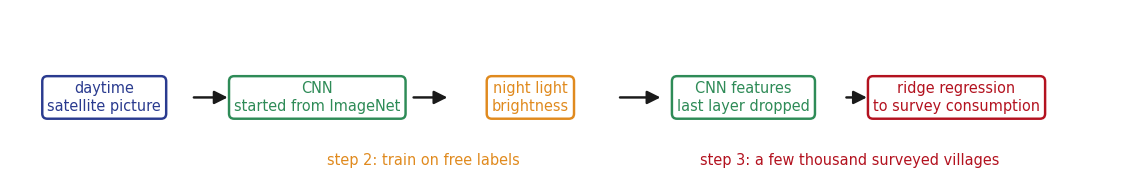

In [43]:
fig, ax = frame((13.2, 2.6), (-0.3, 16.6), (-1.3, 1.3))
boxes = [(1.1, "daytime\nsatellite picture", chh.MADRID), (4.3, "CNN\nstarted from ImageNet", RELU_GREEN),
         (7.5, "night light\nbrightness", POOL), (10.7, "CNN features\nlast layer dropped", RELU_GREEN),
         (13.9, "ridge regression\nto survey consumption", chh.FITLINE)]
for x, text, col in boxes:
    box_label(ax, x, 0.0, text, color=col, fs=9.5, pad=0.35)
arrow(ax, (2.4, 0.0), (3.0, 0.0), lw=1.6)
arrow(ax, (5.7, 0.0), (6.3, 0.0), lw=1.6)
arrow(ax, (8.8, 0.0), (9.5, 0.0), lw=1.6)
arrow(ax, (12.2, 0.0), (12.6, 0.0), lw=1.6)
note(ax, 5.9, -0.95, "step 2: train on free labels", fs=9.5, ha="center", color=POOL)
note(ax, 12.3, -0.95, "step 3: a few thousand surveyed villages", fs=9.5, ha="center", color=chh.FITLINE)

### What It Found

- Consumption per head, four countries, cross validated: <b style="color:#73000A;">37 to 55 percent</b> of the variation across villages explained
- Asset wealth, five countries: <b style="color:#73000A;">55 to 75 percent</b>
- One model pooled across countries: 44 to 59 percent
- Among villages below the poverty line it beats night lights in 81 percent of trials; below three times the line, in 99.5 percent
- Rwanda assets: r² of 0.75, against 0.62 from a study that used mobile phone records, which are proprietary

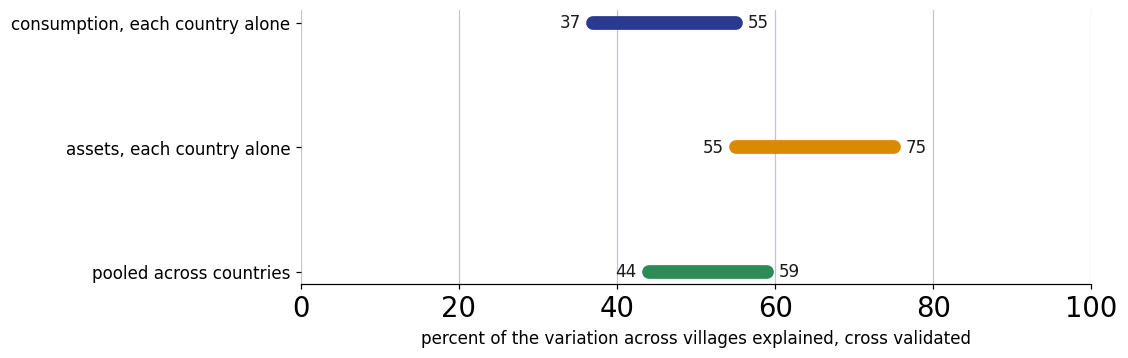

In [44]:
fig, ax = plt.subplots(figsize=(10.6, 3.6), dpi=110)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
ax.grid(True, axis="x", color=chh.GRID, lw=0.8, zorder=0)
ax.set_axisbelow(True)
rows = [("consumption, each country alone", 37, 55, chh.MADRID),
        ("assets, each country alone", 55, 75, chh.ACCENT),
        ("pooled across countries", 44, 59, "#2E8B57")]
for k, (name, lo, hi, col) in enumerate(rows):
    y = len(rows) - 1 - k
    ax.plot([lo, hi], [y, y], color=col, lw=9, solid_capstyle="round", zorder=3)
    ax.text(lo - 1.5, y, "%d" % lo, ha="right", va="center", fontsize=11, color=chh.INK)
    ax.text(hi + 1.5, y, "%d" % hi, ha="left", va="center", fontsize=11, color=chh.INK)
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([r[0] for r in rows][::-1], fontsize=11)
ax.set_xlim(0, 100)
ax.set_xlabel("percent of the variation across villages explained, cross validated", fontsize=11)
for sp in ("top", "right", "left"):
    ax.spines[sp].set_visible(False)
fig.tight_layout()

### What the Filters Look At

- Four of the trained filters light up on <b style="color:#73000A;">urban areas, farmland, water and roads</b>. Nobody told the network to look for those; they are what predicts night lights
- A placebo: shuffle the pictures among villages and refit, 1,000 times. The r² collapses every time. The pictures carry the information, not the fitting
- Roofing material and distance to a town, which surveyors ask about, are things a daytime picture can see

### From Prediction to a Treatment Effect

Ratledge, Cadamuro, de la Cuesta, Stigler and Burke (2022), *Nature* 611, 491 to 495.

- A ResNet-18 CNN reads Landsat tiles, 224 by 224 pixels by 6 bands, trained on <b style="color:#73000A;">27,174 villages</b> in 25 countries, 641,621 surveyed households. Held out r² 0.63
- The predicted wealth becomes the <b style="color:#73000A;">outcome</b>: Uganda's grid expansion, 209 villages electrified and 3,235 not, a prediction for every village every year from 2006 to 2016
- Grid access raised village asset wealth by up to <b style="color:#73000A;">0.15 standard deviations</b>, estimated with panel methods that build each electrified village's counterfactual from the ones still waiting
- The CNN is a measuring device. The identification is the same job as lectures 15 to 19. Lecture 18's appendix runs the reverse, pictures as controls

## Another Application: Reading Body Motion

- Every filter so far slid across a <b style="color:#73000A;">picture</b>: the O, the X, the digits. But a filter does not care what the axis means. Slide it across <b style="color:#73000A;">time</b> instead of space and the same machine reads motion.

- Yang and colleagues used a <b style="color:#73000A;">convolutional neural network</b> to recognize everyday activities (opening a door, drinking from a cup, a tennis swing) from the signals of <b style="color:#73000A;">motion sensors worn on the body</b>.

<span style="font-size:60%;color:#555;">Yang, Nguyen, San, Li &amp; Krishnaswamy, Deep Convolutional Neural Networks on Multichannel Time Series for Human Activity Recognition (IJCAI 2015).</span>

### The Picture Is Now a Motion Clip

An <b style="color:#73000A;">accelerometer</b> worn on the body measures how a limb speeds up and slows down, and a <b style="color:#73000A;">gyroscope</b> measures how it turns. Read them many times a second and every instant is a handful of numbers.

Take a short window and you have a grid of <b style="color:#73000A;">time by channels</b>, one row per sensor axis (below). Each axis is a <b style="color:#73000A;">channel</b>, as red, green and blue were for a photo: 3 accelerometer + 2 gyroscope = 5 channels in

An activity is a small shape in time, and it has to be told apart from the other activities, and from the dominant <b style="color:#73000A;">"Null"</b> class, the long stretches when nothing of interest is happening.

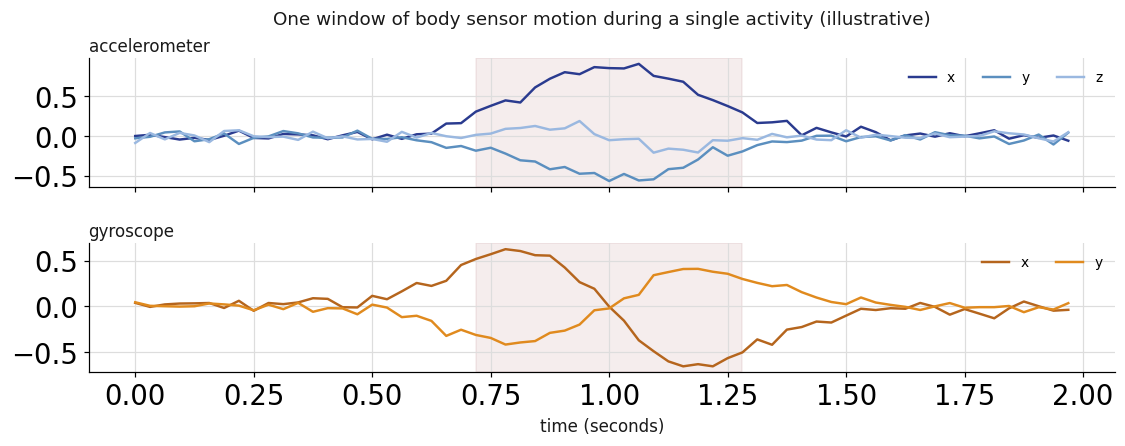

In [45]:
import numpy as np
import matplotlib.pyplot as plt

# Illustrative window of body-worn motion sensors during one activity.
# Yang et al.'s hand-gesture dataset uses a 3-axis accelerometer and a
# 2-axis gyroscope sampled at 32 Hz; the trace below is synthetic, drawn
# only to show the shape a CNN reads. It is not measured data.
rng = np.random.default_rng(7)
fs = 32.0
T = 2.0
n = int(fs * T)
t = np.arange(n) / fs

# a short 'gesture' lives in the middle of the window
c = n // 2
bump = np.exp(-0.5 * ((np.arange(n) - c) / 6.0) ** 2)
d_bump = np.gradient(bump) * fs

ax_ = 0.9 * bump + 0.05 * rng.standard_normal(n)                         # accel x: the swing
ay_ = -0.5 * bump + 0.05 * rng.standard_normal(n)                        # accel y
az_ = 0.2 * np.sin(2 * np.pi * 1.5 * t) * bump + 0.05 * rng.standard_normal(n)  # accel z
gx_ = 0.20 * d_bump + 0.04 * rng.standard_normal(n)                      # gyro x
gy_ = -0.12 * d_bump + 0.04 * rng.standard_normal(n)                     # gyro y

SEG = np.column_stack([ax_, ay_, az_, gx_, gy_])   # (n, 5); reused by the next figure

MADRID, INK, GRID = "#73000A", "#1A1A1A", "#DDDDDD"
acc_c = ["#2A3B8F", "#5B8FBF", "#9AB8E0"]
gyr_c = ["#B5651D", "#E08A1E"]
on = np.where(bump > 0.25)[0]

fig, axs = plt.subplots(2, 1, figsize=(10.6, 4.4), dpi=110, sharex=True)
fig.patch.set_facecolor("white")
for ax, title, data, cols, labs in [
        (axs[0], "accelerometer", SEG[:, :3], acc_c, ["x", "y", "z"]),
        (axs[1], "gyroscope",     SEG[:, 3:], gyr_c, ["x", "y"])]:
    ax.set_facecolor("white")
    if len(on):
        ax.axvspan(t[on[0]], t[on[-1]], color=MADRID, alpha=0.07, zorder=0)
    for j, lab in enumerate(labs):
        ax.plot(t, data[:, j], color=cols[j], lw=1.6, label=lab)
    ax.text(0, 1.02, title, transform=ax.transAxes, ha="left", va="bottom", fontsize=11, color=INK)
    ax.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    ax.legend(loc="upper right", fontsize=9, ncol=3, frameon=False)
axs[1].set_xlabel("time (seconds)", fontsize=11, color=INK)
axs[0].set_title("One window of body sensor motion during a single activity (illustrative)",
                 fontsize=12, color=INK, pad=22)
fig.tight_layout()

### Five Channels, Like Red, Green and Blue

- A color photo is 3 grids stacked, one per color. This clip is <b style="color:#73000A;">5 strips stacked</b>, one per sensor axis: 3 from the accelerometer, 2 from the gyroscope
- Each strip is 2 seconds read 32 times a second: <b style="color:#73000A;">64 readings</b>, so the clip is 5 × 64 = 320 numbers
- A filter covers every channel at once, as the color filter covered all three grids, and slides along <b style="color:#73000A;">time</b> only: 5 strips of 5 weights plus one bias, into one feature map

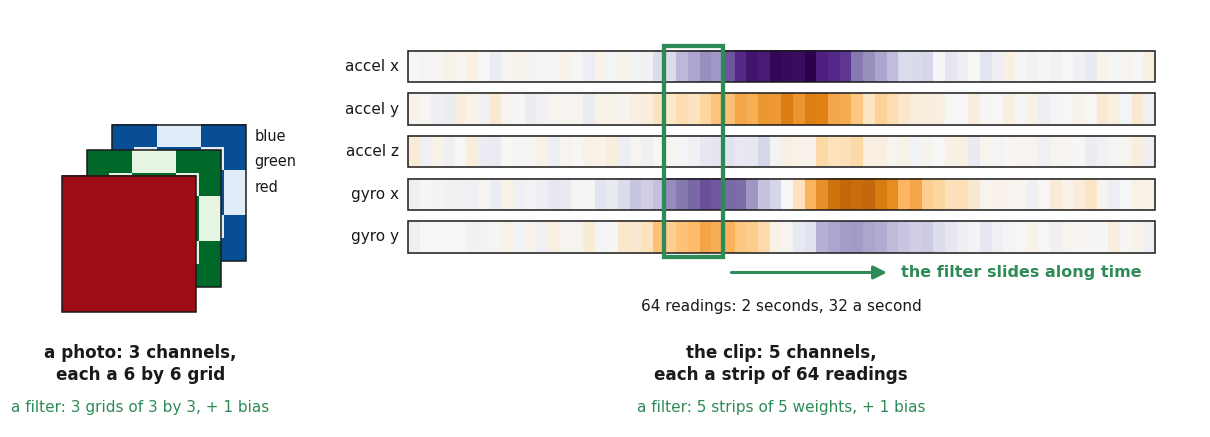

In [46]:
fig, ax = frame((13.6, 4.9), (-0.4, 20.4), (-6.0, 1.3))

# left: the red O as three stacked grids
size, step = 2.4, 0.45
for k, (cmap, name) in reversed(list(enumerate([("Reds", "red"), ("Greens", "green"), ("Blues", "blue")]))):
    x0, y0 = k * step, -4.0 + k * step
    ax.imshow(RED_O[..., k], cmap=cmap, vmin=-0.15, vmax=1.15,
              extent=(x0, x0 + size, y0, y0 + size), zorder=3 + (3 - k))
    ax.add_patch(plt.Rectangle((x0, y0), size, size, fill=False, edgecolor=chh.INK, lw=1.0, zorder=3 + (3 - k)))
    note(ax, 2 * step + size + 0.15, y0 + size - 0.2, name, fs=9.5, color=chh.INK)
note(ax, 1.4, -4.55, "a photo: 3 channels,\neach a 6 by 6 grid", fs=11, ha="center", va="top", weight="bold")
note(ax, 1.4, -5.55, "a filter: 3 grids of 3 by 3, + 1 bias", fs=10, ha="center", va="top", color=RELU_GREEN)

# right: the clip as five stacked strips
x0, x1, h, gap = 6.2, 19.6, 0.55, 0.2
names = ["accel x", "accel y", "accel z", "gyro x", "gyro y"]
top = max(abs(SEG.min()), abs(SEG.max()))
dx = (x1 - x0) / SEG.shape[0]
for j, name in enumerate(names):
    yt = 0.6 - j * (h + gap)
    ax.imshow(SEG[:, j][None, :], cmap="PuOr", vmin=-top, vmax=top, aspect="auto",
              extent=(x0, x1, yt - h, yt), zorder=3)
    ax.add_patch(plt.Rectangle((x0, yt - h), x1 - x0, h, fill=False, edgecolor=chh.INK, lw=1.0, zorder=4))
    note(ax, x0 - 0.15, yt - h / 2, name, fs=10, ha="right")
bottom = 0.6 - 4 * (h + gap) - h
w0 = 22
ax.add_patch(plt.Rectangle((x0 + w0 * dx, bottom - 0.08), 5 * dx, 0.6 - bottom + 0.16, fill=False,
                           edgecolor=RELU_GREEN, lw=2.8, zorder=6))
arrow(ax, (x0 + (w0 + 5) * dx + 0.1, bottom - 0.35), (x0 + (w0 + 5) * dx + 3.0, bottom - 0.35),
      color=RELU_GREEN, lw=2.0)
note(ax, x0 + (w0 + 5) * dx + 3.2, bottom - 0.35, "the filter slides along time", fs=10.5,
     color=RELU_GREEN, weight="bold")
note(ax, (x0 + x1) / 2, bottom - 0.95, "64 readings: 2 seconds, 32 a second", fs=10, ha="center")
note(ax, (x0 + x1) / 2, -4.55, "the clip: 5 channels,\neach a strip of 64 readings", fs=11, ha="center",
     va="top", weight="bold")
note(ax, (x0 + x1) / 2, -5.55, "a filter: 5 strips of 5 weights, + 1 bias", fs=10, ha="center", va="top",
     color=RELU_GREEN)

### The Same Window, as Grids

The green box from the last slide, written out as numbers. It is Overlay, Multiply, Add from the O, with a 5 by 5 window instead of 3 by 3.

- Rows are the 5 channels, columns are 5 readings in a row
- Multiply by the filter cell by cell, add all 25, add the bias: <b style="color:#73000A;">one cell</b> of the feature map
- Slide one reading later and do it again: 64 − 5 + 1 = <b style="color:#73000A;">60</b> cells. The feature map is a strip, not a grid

by hand 0.7529    nn.Conv1d says 0.7529


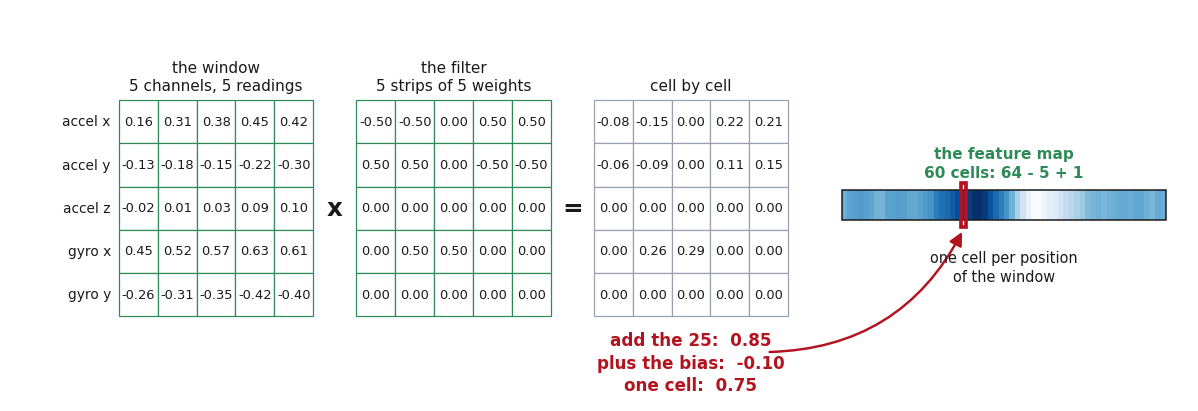

In [47]:
w0 = 22                                     # the green box on the last slide
win = SEG[w0:w0 + 5, :].T                   # (5 channels, 5 readings)
# made up weights: the accelerometer strips look for a rise, gyro x for a turn
CLIP_FILTER = np.array([[-0.5, -0.5, 0.0, 0.5, 0.5],
                        [0.5, 0.5, 0.0, -0.5, -0.5],
                        [0.0, 0.0, 0.0, 0.0, 0.0],
                        [0.0, 0.5, 0.5, 0.0, 0.0],
                        [0.0, 0.0, 0.0, 0.0, 0.0]])
CLIP_BIAS = -0.1
prod = win * CLIP_FILTER
cell_value = prod.sum() + CLIP_BIAS

conv = nn.Conv1d(in_channels=5, out_channels=1, kernel_size=5)
with torch.no_grad():
    conv.weight[:] = torch.tensor(CLIP_FILTER, dtype=torch.float32).unsqueeze(0)
    conv.bias[:] = CLIP_BIAS
    strip = conv(torch.tensor(SEG.T, dtype=torch.float32).unsqueeze(0))[0, 0].numpy()

show = lambda M: np.round(M, 2) + 0.0
fig, ax = frame((13.8, 4.6), (-0.6, 21.2), (-5.0, 1.5))
cell = 0.72
labels = ["accel x", "accel y", "accel z", "gyro x", "gyro y"]
for j, lab in enumerate(labels):
    note(ax, 1.25, -(j + 0.5) * cell, lab, fs=9, ha="right")
grid(ax, show(win), 1.4, 0.0, cell, kind="numbers", fs=8.5, fmt="%.2f", edge=RELU_GREEN,
     title="the window\n5 channels, 5 readings", title_fs=10)
note(ax, 5.4, -1.8, "x", fs=16, ha="center", weight="bold")
grid(ax, show(CLIP_FILTER), 5.8, 0.0, cell, kind="numbers", fs=8.5, fmt="%.2f", edge=RELU_GREEN,
     title="the filter\n5 strips of 5 weights", title_fs=10)
note(ax, 9.8, -1.8, "=", fs=16, ha="center", weight="bold")
grid(ax, show(prod), 10.2, 0.0, cell, kind="numbers", fs=8.5, fmt="%.2f",
     title="cell by cell", title_fs=10)
note(ax, 12.0, -3.85, "add the 25:  %.2f\nplus the bias:  %+.2f\none cell:  %.2f"
     % (prod.sum(), CLIP_BIAS, cell_value), fs=11, ha="center", va="top", color=chh.FITLINE, weight="bold")

# the feature map as a strip of 60
sx0, sx1, sy = 14.8, 20.8, -1.5
cw = (sx1 - sx0) / len(strip)
ax.imshow(strip[None, :], cmap="Blues", aspect="auto", extent=(sx0, sx1, sy - 0.5, sy), zorder=3)
ax.add_patch(plt.Rectangle((sx0, sy - 0.5), sx1 - sx0, 0.5, fill=False, edgecolor=chh.INK, lw=1.0, zorder=4))
ax.add_patch(plt.Rectangle((sx0 + w0 * cw, sy - 0.62), cw, 0.74, fill=False, edgecolor=chh.FITLINE, lw=2.4, zorder=5))
note(ax, (sx0 + sx1) / 2, sy + 0.45, "the feature map\n60 cells: 64 - 5 + 1", fs=10, ha="center",
     color=RELU_GREEN, weight="bold")
note(ax, (sx0 + sx1) / 2, sy - 1.0, "one cell per position\nof the window", fs=9.5, ha="center", va="top")
arrow(ax, (13.4, -4.2), (sx0 + (w0 + 0.5) * cw, sy - 0.65), color=chh.FITLINE, lw=1.6, rad=0.3)
print("by hand %.4f    nn.Conv1d says %.4f" % (cell_value, strip[w0]))

### Some Problems




- <b style="color:#73000A;">Too many weights.</b> A few seconds across several axes is already hundreds of numbers. A plain network ties a weight to every one.
- <b style="color:#73000A;">It can happen anywhere.</b> The activity can start at any moment in the window, just as the letter could sit anywhere in the image.
- <b style="color:#73000A;">Neighbors look alike.</b> Two readings a fraction of a second apart are nearly identical, so one number on its own says almost nothing.

The fix is the same filter, slid along the clip. One dimension instead of two: <b style="color:#73000A;">time</b>.

### The Filter Slides Across Time

In the paper the convolution and pooling filters run <b style="color:#73000A;">along the time axis</b>, one sensor channel at a time. A filter is a short strip of weights, here <b style="color:#73000A;">5 readings wide</b>. Lay it over the start of the signal, multiply, add, write down one number: Overlay, Multiply, Add from the O, on a strip instead of a square. Slide it forward and do it again.

The row of numbers it leaves behind is the <b style="color:#73000A;">feature map</b>, and it lights up wherever the signal has the little shape the filter is looking for, no matter <b style="color:#73000A;">when</b> that shape happens.

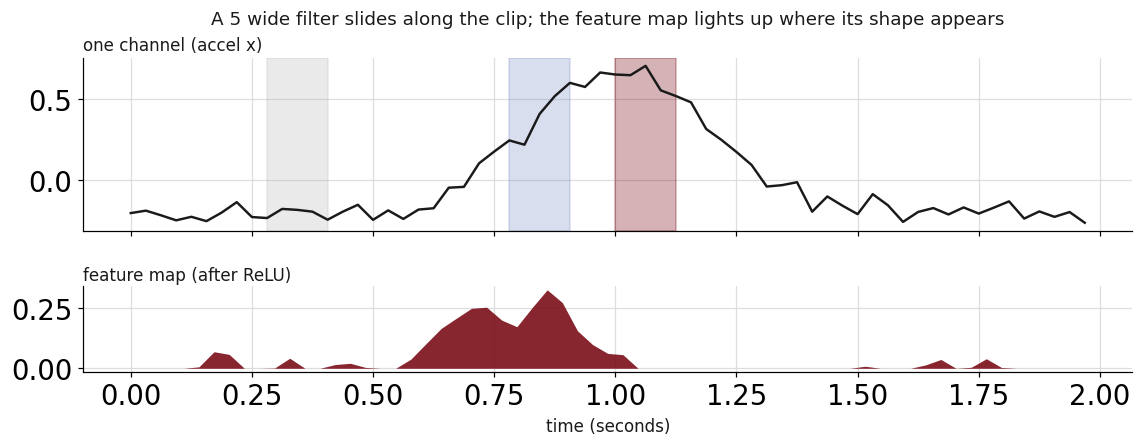

In [48]:
import numpy as np
import matplotlib.pyplot as plt

MADRID, INK, GRID = "#73000A", "#1A1A1A", "#DDDDDD"

ch = SEG[:, 0].astype(float)          # one channel: accelerometer x
ch = ch - ch.mean()
fs = 32.0
t = np.arange(len(ch)) / fs

# a tiny 5-wide filter that responds to a rise-then-fall motion
w = np.array([-1., -1., 0., 1., 1.]) / 2.0
fmap = np.maximum(np.correlate(ch, w, mode="valid"), 0.0)   # slide + ReLU
tm = (np.arange(len(fmap)) + len(w) / 2) / fs

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10.6, 4.4), dpi=110, sharex=True,
                             gridspec_kw={"height_ratios": [2, 1]})
fig.patch.set_facecolor("white")
for a in (a1, a2):
    a.set_facecolor("white")
    a.grid(True, color=GRID, lw=0.8); a.set_axisbelow(True)
    for sp in ("top", "right"):
        a.spines[sp].set_visible(False)

a1.plot(t, ch, color=INK, lw=1.6, zorder=3)
L = len(ch)
for frac, col in [(0.15, "#BBBBBB"), (0.40, "#7F93C8"), (0.50, MADRID)]:
    p = int(frac * L)
    if p + 5 <= L:
        a1.axvspan(t[p], t[p + 4], color=col, alpha=0.30, zorder=1)
a1.text(0, 1.02, "one channel (accel x)", transform=a1.transAxes, ha="left", va="bottom", fontsize=11, color=INK)
a1.set_title("A 5 wide filter slides along the clip; the feature map lights up where its shape appears",
             fontsize=12, color=INK, pad=22)

a2.fill_between(tm, fmap, color=MADRID, alpha=0.85, lw=0)
a2.text(0, 1.02, "feature map (after ReLU)", transform=a2.transAxes, ha="left", va="bottom", fontsize=11, color=INK)
a2.set_xlabel("time (seconds)", fontsize=11, color=INK)
fig.tight_layout()

### Channels: Kept Apart or Added Up

Five sensor channels, and two ways to slide a filter over them.

- <b style="color:#73000A;">Kept apart</b>, as in the paper: each filter reads one sensor at a time. Treat the clip as a one channel picture, time by sensors, with a 5 by 1 filter: `nn.Conv2d(1, 50, kernel_size=(5, 1))`. The sensors only meet later, in the unification layer
- <b style="color:#73000A;">Added up</b>, the usual way today: each filter has one strip per sensor and adds the five into one map, as the color filter added its three grids: `nn.Conv1d(in_channels=5, out_channels=50, kernel_size=5)`
- The Keras code two slides on is the second kind

In [49]:
clip = torch.tensor(SEG[:32].T, dtype=torch.float32).unsqueeze(0)    # (1 clip, 5 sensors, 32 readings)

apart = nn.Conv2d(1, 50, kernel_size=(5, 1))          # the clip as a 32 by 5 picture, one channel
added = nn.Conv1d(in_channels=5, out_channels=50, kernel_size=5)

with torch.no_grad():
    pic = clip.transpose(1, 2).unsqueeze(1)           # (1, 1, 32 readings, 5 sensors)
    print("kept apart  input %-16s -> %-18s weights %s  parameters %d"
          % (tuple(pic.shape), tuple(apart(pic).shape), tuple(apart.weight.shape),
             sum(p.numel() for p in apart.parameters())))
    print("added up    input %-16s -> %-18s weights %s  parameters %d"
          % (tuple(clip.shape), tuple(added(clip).shape), tuple(added.weight.shape),
             sum(p.numel() for p in added.parameters())))
print()
print("kept apart: 50 maps, 28 readings long, for each of the 5 sensors")
print("added up:   50 maps, 28 readings long, each already mixing all 5 sensors")

kept apart  input (1, 1, 32, 5)    -> (1, 50, 28, 5)     weights (50, 1, 5, 1)  parameters 300
added up    input (1, 5, 32)       -> (1, 50, 28)        weights (50, 5, 5)  parameters 1300

kept apart: 50 maps, 28 readings long, for each of the 5 sensors
added up:   50 maps, 28 readings long, each already mixing all 5 sensors


### The Whole Machine

Stack these and you have the paper's CNN.

- A <b style="color:#73000A;">Conv1D</b> layer slides many filters across the window, each followed by <b style="color:#73000A;">ReLU</b>, <b style="color:#73000A;">max pooling</b> and normalization
- A second and third convolution read patterns made of the earlier layers' patterns, at coarser time scales
- A <b style="color:#73000A;">unification</b> layer then ties together the separate sensor channels into one shared representation
- A <b style="color:#73000A;">softmax</b> maps that onto the activity classes

Same ingredients as the image CNN, plus one new piece: the layer that unifies the channels. `Conv2d` becomes `Conv1D`; the grid becomes a clip.

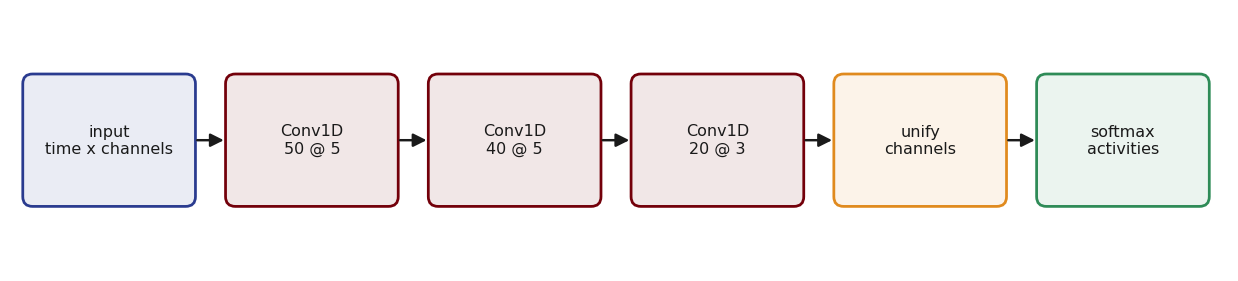

In [50]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

MADRID, INK = "#73000A", "#1A1A1A"
BLUE, ORANGE, GREEN, GREY = "#2A3B8F", "#E08A1E", "#2E8B57", "#777777"

fig, ax = plt.subplots(figsize=(11.6, 2.9), dpi=110)
fig.patch.set_facecolor("white"); ax.set_facecolor("white"); ax.axis("off")
ax.set_xlim(0, 18.6); ax.set_ylim(0, 4)

blocks = [("input\ntime x channels", 0.2, BLUE),
          ("Conv1D\n50 @ 5", 3.3, MADRID),
          ("Conv1D\n40 @ 5", 6.4, MADRID),
          ("Conv1D\n20 @ 3", 9.5, MADRID),
          ("unify\nchannels", 12.6, ORANGE),
          ("softmax\nactivities", 15.7, GREEN)]
w, h, y = 2.6, 2.0, 1.0
for text, x, col in blocks:
    ax.add_patch(FancyBboxPatch((x, y), w, h,
                 boxstyle="round,pad=0.02,rounding_size=0.15",
                 linewidth=1.8, edgecolor=col, facecolor=col + "18"))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center",
            fontsize=10.5, color=INK)
for i in range(len(blocks) - 1):
    x0 = blocks[i][1] + w
    x1 = blocks[i + 1][1]
    ax.annotate("", xy=(x1, y + h / 2), xytext=(x0, y + h / 2),
                arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.6))
fig.tight_layout()

### In Keras

```python
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense

model = Sequential([
    Conv1D(50, 5, activation="relu", input_shape=(32, 5)),  # time steps, sensor channels
    MaxPooling1D(2),

    Conv1D(40, 5, activation="relu"),
    MaxPooling1D(2),

    Conv1D(20, 3, activation="relu"),

    Flatten(),
    Dense(400, activation="relu"),        # fully connected, like the paper's unification layer
    Dense(12, activation="softmax"),      # activity classes
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
```

A handful of lines. Swap a 2D convolution for a 1D one and the image CNN becomes a motion CNN.

### In PyTorch


In [51]:
motion = nn.Sequential(
    nn.Conv1d(5, 50, kernel_size=5), nn.ReLU(), nn.MaxPool1d(2),
    nn.Conv1d(50, 40, kernel_size=5), nn.ReLU(), nn.MaxPool1d(2),
    nn.Conv1d(40, 20, kernel_size=3), nn.ReLU(),
    nn.Flatten(),
    nn.Linear(20 * 3, 400), nn.ReLU(),
    nn.Linear(400, 12),                     # 12 activity classes, then SoftMax and cross entropy
)
def describe(layer):
    if isinstance(layer, nn.Conv1d):
        return "Conv1d(%d, %d, %d)" % (layer.in_channels, layer.out_channels, layer.kernel_size[0])
    if isinstance(layer, nn.MaxPool1d):
        return "MaxPool1d(%d)" % layer.kernel_size
    if isinstance(layer, nn.Linear):
        return "Linear(%d, %d)" % (layer.in_features, layer.out_features)
    return type(layer).__name__


x = clip
print("%-34s %s" % ("the clip, (clips, sensors, readings)", tuple(x.shape)))
with torch.no_grad():
    for layer in motion:
        x = layer(x)
        if not isinstance(layer, nn.ReLU):
            print("%-34s %s" % (describe(layer), tuple(x.shape)))
print()
print("parameters:", format(sum(p.numel() for p in motion.parameters()), ","))

the clip, (clips, sensors, readings) (1, 5, 32)
Conv1d(5, 50, 5)                   (1, 50, 28)
MaxPool1d(2)                       (1, 50, 14)
Conv1d(50, 40, 5)                  (1, 40, 10)
MaxPool1d(2)                       (1, 40, 5)
Conv1d(40, 20, 3)                  (1, 20, 3)
Flatten                            (1, 60)
Linear(60, 400)                    (1, 400)
Linear(400, 12)                    (1, 12)

parameters: 42,972


## Case Study: From Door Handles to Tennis Swings

The authors tested the same CNN on two very different motion datasets: one of <b style="color:#73000A;">whole body</b> activity around a kitchen (opening doors, drawers and the fridge, drinking from a cup) and one of <b style="color:#73000A;">hand gestures</b>, from stirring a bowl to a tennis forehand, backhand and smash.

A brief, meaningful motion has to be picked out of a long stream that is mostly the <b style="color:#73000A;">"Null"</b> class, ordinary movement that means nothing.

### What the Study Found

Against four baselines (an <b style="color:#73000A;">SVM</b>, nearest-neighbor, handcrafted mean and variance features, and a <b style="color:#73000A;">deep belief network</b>) the CNN came out on top on <b style="color:#73000A;">both</b> datasets, across every metric.

On the hand-gesture data it reached about <b style="color:#73000A;">95 percent</b> accuracy, and on the hardest subjects it beat the best handcrafted feature baseline by roughly <b style="color:#73000A;">5 points</b>. Because the filters are <b style="color:#73000A;">learned</b> rather than designed by hand, the same network transfers from one activity set to the other.

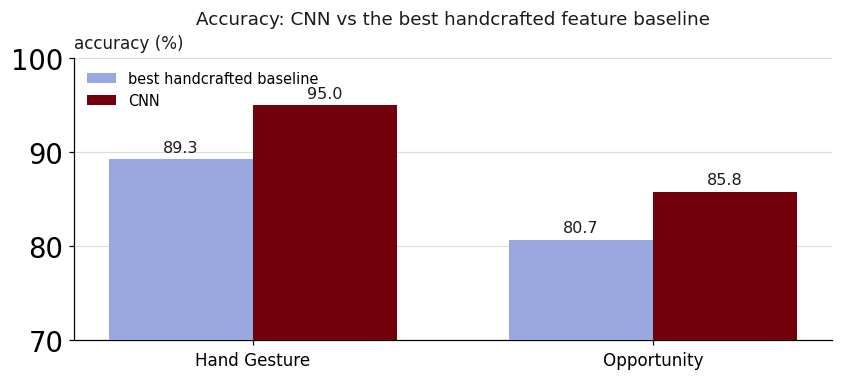

In [52]:
import numpy as np
import matplotlib.pyplot as plt

MADRID, INK, GRID = "#73000A", "#1A1A1A", "#DDDDDD"

groups = ["Hand Gesture", "Opportunity"]
cnn      = [95.0, 85.8]
baseline = [89.3, 80.7]

x = np.arange(len(groups))
wd = 0.36
fig, ax = plt.subplots(figsize=(8.0, 3.8), dpi=110)
fig.patch.set_facecolor("white"); ax.set_facecolor("white")
b1 = ax.bar(x - wd / 2, baseline, wd, label="best handcrafted baseline",
            color="#9AA8E0", zorder=3)
b2 = ax.bar(x + wd / 2, cnn, wd, label="CNN", color=MADRID, zorder=3)
ax.grid(True, axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.4,
                "%.1f" % b.get_height(), ha="center", va="bottom",
                fontsize=10.5, color=INK)
ax.set_xticks(x); ax.set_xticklabels(groups, fontsize=11)
ax.text(0, 1.02, "accuracy (%)", transform=ax.transAxes, ha="left", va="bottom", fontsize=11, color=INK)
ax.set_ylim(70, 100)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
ax.legend(loc="upper left", fontsize=9.5, frameon=False)
ax.set_title("Accuracy: CNN vs the best handcrafted feature baseline",
             fontsize=12, color=INK, pad=22)
fig.tight_layout()

### Learned Filters, Not Handcrafted Features

The older methods lived or died by the features a person chose: the mean, the variance, a Fourier transform of each window. The CNN skips that step: the convolution filters are <b style="color:#73000A;">learned from the labels</b>, so they tune themselves to whatever shape actually separates the activities.

That the CNN also beats the deep belief network, a deep model trained <b style="color:#73000A;">without</b> the labels, is the paper's quiet point: for this problem, learning the filters <b style="color:#73000A;">under supervision</b> is what carries the signal.

### Why It Is the Same Machine

An activity is a small, local shape in the motion that can land anywhere in the window. That is just what a sliding filter is built to find.

The O and the X were shapes in <b style="color:#73000A;">space</b>; a door pull or a tennis swing is a shape in <b style="color:#73000A;">time</b>. One fewer dimension, the same idea: a filter that slides, a feature map, ReLU, pooling, plus one new step that unifies the separate sensor channels.

## Key Ideas

- A <b style="color:#73000A;">filter</b> is a small square of weights slid across the picture. Multiply, add, add a bias: a <b style="color:#73000A;">feature map</b>
- <b style="color:#73000A;">ReLU</b>, then <b style="color:#73000A;">max pooling</b>: keep the largest value in each block. Fewer inputs, and a small shift leaves the answer alone
- The pooled grid becomes a column into an ordinary network, trained by backpropagation with cross entropy. 36 pixels became 4 inputs
- The filter reads neighbors together, which is what pixels one at a time cannot do
- Color is three <b style="color:#73000A;">channels</b>. A filter is three grids and one bias. Gray throws the color away
- Many filters make many maps, and those maps are the next layer's channels
- Nothing about a filter needs a picture. Slide it along <b style="color:#73000A;">time</b> and the same machine reads motion; each sensor axis is a channel
- `nn.Conv2d`, `nn.MaxPool2d`, `nn.Linear`
- In economics the CNN is mostly a <b style="color:#73000A;">measuring device</b>: it turns pictures into numbers that a regression then uses